# [PBT] 모델링 전 국가별 데이터셋 전처리
## #01. 준비작업
### 1-1. 라이브러리 참조

In [1]:
# import sys
# sys.path.append("D:\\")

from IPython.display import display, Markdown
from pandas import DataFrame, crosstab
from helpers import * 

### 1-2. 파일 불러오기

In [2]:
import pandas as pd

df = pd.read_excel("토픽분류_데이터셋.xlsx")

display(df.head())
display(df.tail())

,리뷰_번호,국가,제품_순위,별점,Y,보습,향,발림성,자극,용기,배송,기능,가격,브랜드충성도
0,RU_P01_0001,러시아,1,5,1,0,0,1,0,1,0,1,0,0
1,RU_P01_0002,러시아,1,5,1,1,0,0,0,0,0,0,0,0
2,RU_P01_0003,러시아,1,5,1,1,1,0,0,1,0,1,0,0
3,RU_P01_0004,러시아,1,5,1,0,0,0,0,0,0,0,0,0
4,RU_P01_0005,러시아,1,5,1,0,1,1,0,1,1,0,0,0


,리뷰_번호,국가,제품_순위,별점,Y,보습,향,발림성,자극,용기,배송,기능,가격,브랜드충성도
7225,KR_P10_0196,한국,10,2,0,1,1,1,1,0,0,0,0,0
7226,KR_P10_0197,한국,10,2,0,0,0,1,1,0,0,0,0,0
7227,KR_P10_0198,한국,10,2,0,0,0,0,1,0,0,0,0,0
7228,KR_P10_0199,한국,10,2,0,1,0,0,1,0,0,0,0,0
7229,KR_P10_0200,한국,10,2,0,1,0,0,0,0,0,0,0,0


### 1-3. 컬럼 의미를 정리한 딕셔너리

In [3]:
column_means = {
    "리뷰_번호": "'국가 코드(러시아->RU, 미국->US, 일본->JP, 한국->KR)'_'제품 순위'_'리뷰 한 건'의 조합 구분자",
    "국가":    "러시아, 미국, 일본, 한국",
    "제품 순위":      "각 국가의 대표 플랫폼에서 수집한 스킨케어 크림 제품 인기 상위 순위. 1~10위",
    "Y":        "소비자의 제품 만족 여부. 0=불만족(별점 1·2점) / 1=만족(별점 4·5점) / 별점 3점은 제거",
    "보습":         "크림 제품의 보습력",
    "향":         "제품의 향",
    "발림성":       "제품의 제형·사용 후 느낌·흡수력",
    "자극":       "제품의 피부 자극·트러블 생성",
    "용기":      "제품 용기의 디자인, 패키지 구성, 밀봉력, 용량, 유통기한, 사용의 편리함",
    "배송":        "배송 속도, 제품 보존력, 주문 누락·오배송",
    "기능":       "제품의 효과",
    "가격":    "소비자가 느낀 비쌈/저렴함, 할인·쿠폰 적용 여부",
    "브랜드충성도":    "소비자의 브랜드 신뢰, 제품의 시리즈 선호, 이전 구매에서의 긍정적인 경험"
}

> 1행 = 리뷰 1건. 하나의 리뷰를 절 단위 조각으로 나누지 않음

> 9개의 토픽: 소비자의 만족도에 영향을 주는 각 요소가 리뷰에서 언급되었는지 여부(0=언급되지 않음/1=언급됨)

## #02. 데이터 품질 점검

### 2-1. 자료형 확인

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7230 entries, 0 to 7229
Data columns (total 14 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   리뷰_번호   7230 non-null   str  
 1   국가      7230 non-null   str  
 2   제품_순위   7230 non-null   int64
 3   별점      7230 non-null   int64
 4   Y       7230 non-null   int64
 5   보습      7230 non-null   int64
 6   향       7230 non-null   int64
 7   발림성     7230 non-null   int64
 8   자극      7230 non-null   int64
 9   용기      7230 non-null   int64
 10  배송      7230 non-null   int64
 11  기능      7230 non-null   int64
 12  가격      7230 non-null   int64
 13  브랜드충성도  7230 non-null   int64
dtypes: int64(12), str(2)
memory usage: 916.3 KB


### 2-2. 데이터 타입 변환

In [5]:
df_typed = my_qtcheck.set_type(df, as_category=['국가', '제품_순위'])

<class 'pandas.DataFrame'>
RangeIndex: 7230 entries, 0 to 7229
Data columns (total 14 columns):
 #   Column  Non-Null Count  Dtype   
---  ------  --------------  -----   
 0   리뷰_번호   7230 non-null   str     
 1   국가      7230 non-null   category
 2   제품_순위   7230 non-null   category
 3   별점      7230 non-null   int64   
 4   Y       7230 non-null   int64   
 5   보습      7230 non-null   int64   
 6   향       7230 non-null   int64   
 7   발림성     7230 non-null   int64   
 8   자극      7230 non-null   int64   
 9   용기      7230 non-null   int64   
 10  배송      7230 non-null   int64   
 11  기능      7230 non-null   int64   
 12  가격      7230 non-null   int64   
 13  브랜드충성도  7230 non-null   int64   
dtypes: category(2), int64(11), str(1)
memory usage: 769.9 KB


- 컬럼 중 `국가`·`제품_순위`를 **명목형(category)** 으로 변환한다.
 - `국가`: 고유값 4개(**러시아/미국/일본/한국**)를 가지는 명목형이다. 모델 투입 시엔 이후 원-핫 인코딩이 필요하므로 연속형으로 두면 안 된다.
 - `제품_순위`: 숫자 1~10(**인기순 상위 10개**)이지만 국가별로 다른 제품을 가리키는 **식별자 성격**이라 연속형으로 두면 안 된다. 명목형으로 취급 후 원-핫 인코딩 필요하다.

> `Y(종속변수)`: 이미 0/1 이진값이라 int 상태로도 sklearn에 바로 사용 가능. category로 바꿔도 되지만 필수는 아님

> `보습`·`향`·`발림성`·`자극`·`용기`·`배송`·`기능`·`가격`·`브랜드충성도` (토픽 9개): 변환 불필요(category로 바꿀 필요 없음). "언급 여부"를 나타내는 더미/이진 인디케이터라 이미 모델 투입 가능한 형태.    
다만 메모리 절약 목적이면 int64 → int8 또는 bool로 다운캐스팅은 고려 가능

### 2-3. 데이터 중복 점검

In [6]:
df_unique = my_qtcheck.check_duplicates(df_typed, drop=True)

print("중복 점검 후 :", df_unique.shape)

중복된 행의 수: 0
중복 점검 후 : (7230, 14)


### 2-4. 불필요한 컬럼 제거

| 컬럼 | 처리 |
|---|---|
| `리뷰_번호` | **행마다 고유한 ID**이므로 category로 바꿔도 이득이 없고, 모델링 피처에서는 제외(드롭) 대상 |
| `별점` | Y가 별점에서 그대로 파생된 값(1·2점→0, 4·5점→1)이라 피처로 쓰면 데이터 누수(leakage) 발생 → category 변환이 아니라 컬럼 자체를 드롭 |

In [7]:
# 중복이 없었으므로 행 수는 그대로다. 여기서 분석에 쓸 수 없는 컬럼만 떨어낸다.
# -> `국가` 는 파생변수(국가x속성)의 재료이므로 여기서 지우지 않는다 (#03.5 에서 제거)
df_dropped = df_unique.drop(columns=["리뷰_번호", "별점"])

df_dropped.info()

<class 'pandas.DataFrame'>
RangeIndex: 7230 entries, 0 to 7229
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype   
---  ------  --------------  -----   
 0   국가      7230 non-null   category
 1   제품_순위   7230 non-null   category
 2   Y       7230 non-null   int64   
 3   보습      7230 non-null   int64   
 4   향       7230 non-null   int64   
 5   발림성     7230 non-null   int64   
 6   자극      7230 non-null   int64   
 7   용기      7230 non-null   int64   
 8   배송      7230 non-null   int64   
 9   기능      7230 non-null   int64   
 10  가격      7230 non-null   int64   
 11  브랜드충성도  7230 non-null   int64   
dtypes: category(2), int64(10)
memory usage: 579.2 KB


### 2-5. 결측치 점검

In [8]:
my_qtcheck.check_missing_values(df_dropped)

,Missing Count,Missing Ratio (%)
국가,0,0.0
제품_순위,0,0.0
Y,0,0.0
보습,0,0.0
향,0,0.0
발림성,0,0.0
자극,0,0.0
용기,0,0.0
배송,0,0.0
기능,0,0.0


### 2-6. 속성값이 모두 0인 행 개수 확인
- 토픽의 속성값이 모두 0이다: 소비자의 평가는 있으나, 분석가가 분류한 토픽이 리뷰에 언급되지 않음.


In [9]:
cols = [
    '보습', '향', '발림성', '자극', 
    '용기', '배송', '기능', '가격', '브랜드충성도'
]

# 9개 속성이 모두 0인 행 찾기
zero_rows = (df_dropped[cols] == 0).all(axis=1)

# 전체 개수 확인
print("속성값이 모두 0인 행 개수:", zero_rows.sum())

# 국가별 개수 확인
print("\n국가별 속성값 전체 0인 행 개수:")
display(df_dropped.loc[zero_rows, '국가'].value_counts())

# 해당 행 직접 확인
display(df_dropped[zero_rows])

속성값이 모두 0인 행 개수: 474

국가별 속성값 전체 0인 행 개수:


국가
러시아    234
한국     107
미국      89
일본      44
Name: count, dtype: int64

,국가,제품_순위,Y,보습,향,발림성,자극,용기,배송,기능,가격,브랜드충성도
3,러시아,1,1,0,0,0,0,0,0,0,0,0
8,러시아,1,1,0,0,0,0,0,0,0,0,0
22,러시아,1,1,0,0,0,0,0,0,0,0,0
32,러시아,1,1,0,0,0,0,0,0,0,0,0
38,러시아,1,1,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
7102,한국,10,1,0,0,0,0,0,0,0,0,0
7111,한국,10,1,0,0,0,0,0,0,0,0,0
7120,한국,10,1,0,0,0,0,0,0,0,0,0
7124,한국,10,1,0,0,0,0,0,0,0,0,0


### 2-7. 속성값이 모두 0인 행 제거

In [10]:
df_cleaned = df_dropped.loc[~zero_rows].copy()

print("삭제 전 행 개수:", len(df_dropped))
print("삭제 후 행 개수:", len(df_cleaned))
print("삭제된 행 개수:", len(df_dropped) - len(df_cleaned))

display(df_cleaned.head())

삭제 전 행 개수: 7230
삭제 후 행 개수: 6756
삭제된 행 개수: 474


,국가,제품_순위,Y,보습,향,발림성,자극,용기,배송,기능,가격,브랜드충성도
0,러시아,1,1,0,0,1,0,1,0,1,0,0
1,러시아,1,1,1,0,0,0,0,0,0,0,0
2,러시아,1,1,1,1,0,0,1,0,1,0,0
4,러시아,1,1,0,1,1,0,1,1,0,0,0
5,러시아,1,1,1,0,0,0,0,0,0,0,0


In [11]:
df_cleaned.to_excel("df_cleaned.xlsx", index=False)
print("결측치 제거한 데이터셋 저장:", df_cleaned)

결측치 제거한 데이터셋 저장:        국가 제품_순위  Y  보습  향  발림성  자극  용기  배송  기능  가격  브랜드충성도
0     러시아     1  1   0  0    1   0   1   0   1   0       0
1     러시아     1  1   1  0    0   0   0   0   0   0       0
2     러시아     1  1   1  1    0   0   1   0   1   0       0
4     러시아     1  1   0  1    1   0   1   1   0   0       0
5     러시아     1  1   1  0    0   0   0   0   0   0       0
...   ...   ... ..  .. ..  ...  ..  ..  ..  ..  ..     ...
7225   한국    10  0   1  1    1   1   0   0   0   0       0
7226   한국    10  0   0  0    1   1   0   0   0   0       0
7227   한국    10  0   0  0    0   1   0   0   0   0       0
7228   한국    10  0   1  0    0   1   0   0   0   0       0
7229   한국    10  0   1  0    0   0   0   0   0   0       0

[6756 rows x 12 columns]


## #03. 도메인 지식에 기반한 파생변수 및 분석용 자료형 설정

In [12]:
## #03. 도메인 지식에 기반한 파생변수 추가

topic_cols = [
    '보습', '향', '발림성', '자극',
    '용기', '배송', '기능', '가격', '브랜드충성도'
]

# 속성 전체 0인 행을 제거한 데이터 사용
df_derived = df_cleaned.copy()

# 한 리뷰에서 몇 개의 속성이 언급되었는지
df_derived['토픽_언급수'] = df_derived[topic_cols].sum(axis=1)

column_means['토픽_언급수'] = '한 리뷰에서 언급된 9개 속성의 개수'

display(
    df_derived['토픽_언급수']
    .value_counts()
    .sort_index()
)

토픽_언급수
1    1658
2    2320
3    1719
4     846
5     168
6      38
7       6
8       1
Name: count, dtype: int64

# 03. 도메인 지식에 기반한 파생변수 추가

## 1. 토픽 언급 수 파생변수 생성

- 각 리뷰에서 9개 속성 중 몇 개의 속성이 언급되었는지 확인하기 위해 `토픽_언급수` 변수를 생성한다.
- 분석 대상 속성은 `보습`, `향`, `발림성`, `자극`, `용기`, `배송`, `기능`, `가격`, `브랜드충성도` 총 9개이다.
- 각 속성은 언급되지 않은 경우 `0`, 언급된 경우 `1`로 구성되어 있으므로, 9개 속성의 값을 합산하여 리뷰별 토픽 언급 수를 계산한다.
- 앞 단계에서 9개 속성이 모두 0인 리뷰를 제거하였으므로 `토픽_언급수`의 최솟값은 1이다.

### 토픽 언급 수 분포

- 1개 속성 언급: 1,468건
- 2개 속성 언급: 2,234건
- 3개 속성 언급: 1,836건
- 4개 속성 언급: 979건
- 5개 속성 언급: 237건
- 6개 속성 언급: 49건
- 7개 속성 언급: 9건
- 8개 속성 언급: 1건

대부분의 리뷰에서 2~3개의 속성이 함께 언급되는 경향을 확인할 수 있다.

`토픽_언급수`는 개별 속성의 효과를 대체하는 변수가 아니라, 리뷰 한 건에서 얼마나 다양한 속성이 함께 언급되었는지를 나타내는 보조 파생변수로 활용한다.

## #04. 결측치 최종 확인


In [13]:
my_qtcheck.check_missing_values(df_derived)

,Missing Count,Missing Ratio (%)
국가,0,0.0
제품_순위,0,0.0
Y,0,0.0
보습,0,0.0
향,0,0.0
발림성,0,0.0
자극,0,0.0
용기,0,0.0
배송,0,0.0
기능,0,0.0


## #05. 기술통계량 확인


In [14]:

df_eda = df_derived.copy()

# EDA에서 범주형으로 사용할 변수
eda_category_cols = [
    'Y', '국가', '제품_순위',
    '보습', '향', '발림성', '자극',
    '용기', '배송', '기능', '가격', '브랜드충성도'
]

df_eda = my_qtcheck.set_type(
    df_eda,
    as_category=eda_category_cols
)

cat_desc = my_qtcheck.categorical_summary(
    df_eda,
    value_counts=False
)

cat_desc

<class 'pandas.DataFrame'>
Index: 6756 entries, 0 to 7229
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype   
---  ------  --------------  -----   
 0   국가      6756 non-null   category
 1   제품_순위   6756 non-null   category
 2   Y       6756 non-null   category
 3   보습      6756 non-null   category
 4   향       6756 non-null   category
 5   발림성     6756 non-null   category
 6   자극      6756 non-null   category
 7   용기      6756 non-null   category
 8   배송      6756 non-null   category
 9   기능      6756 non-null   category
 10  가격      6756 non-null   category
 11  브랜드충성도  6756 non-null   category
 12  토픽_언급수  6756 non-null   int64   
dtypes: category(12), int64(1)
memory usage: 185.2 KB


,국가,제품_순위,Y,보습,향,발림성,자극,용기,배송,기능,가격,브랜드충성도
count,6756,6756,6756,6756,6756,6756,6756,6756,6756,6756,6756,6756
unique,4,10,2,2,2,2,2,2,2,2,2,2
top,한국,8,1,0,0,0,0,0,0,0,0,0
freq,1832,741,4420,3657,5657,3603,3712,5364,6329,4284,6208,6033


# 05. 분석용 자료형 설정 및 기술통계 확인

## 1. EDA용 변수 자료형 설정

분석 목적에 맞게 EDA용 데이터프레임을 별도로 생성하고 변수의 자료형을 재설정하였다.

- 전체 분석 대상 데이터는 6,813건이다.
- 종속변수 `Y`, `국가`, `제품_순위` 및 9개 속성 변수는 범주형(`category`)으로 변환하였다.
- 속성 변수는 값이 0과 1로 구성되어 있으나, 수치의 크기를 의미하는 변수가 아니라 속성의 미언급(0)과 언급(1)을 나타내므로 범주형 변수로 처리하였다.
- `국가`와 `제품_순위` 역시 연속적인 크기나 순서를 의미하는 수치형 변수가 아니므로 범주형으로 처리하였다.
- `토픽_언급수`는 리뷰 한 건에서 언급된 속성의 개수를 의미하므로 수치형(`int64`)으로 유지하였다.
- 모든 변수의 Non-Null Count가 6,813건으로 동일하므로 현재 분석 데이터에는 결측치가 존재하지 않는다.

### 자료형 구성

- 범주형 변수: 12개
    - Y
    - 국가
    - 제품_순위
    - 보습
    - 향
    - 발림성
    - 자극
    - 용기
    - 배송
    - 기능
    - 가격
    - 브랜드충성도

- 수치형 변수: 1개
    - 토픽_언급수

따라서 이후 단변량 및 이변량 분석에서는 범주형 변수에 대해 빈도분석과 교차분석을 중심으로 수행하고, `토픽_언급수`는 수치형 파생변수로 별도 분석한다.

## #06. 변수 유형 분류와 EDA 범위


In [15]:

target = 'Y'
target_is_continuous = False

nominal_cols = my_qtcheck.get_categorical_column_names(df_eda)
continuous_cols = my_qtcheck.get_number_column_names(df_eda)

# 종속변수 제거
nominal_cols.remove(target)

print("종속변수 :", target)
print("종속변수 유형 : 명목형(2집단)")
print("명목형 독립변수 :", nominal_cols)
print("연속형 독립변수 :", continuous_cols)

종속변수 : Y
종속변수 유형 : 명목형(2집단)
명목형 독립변수 : ['국가', '제품_순위', '보습', '향', '발림성', '자극', '용기', '배송', '기능', '가격', '브랜드충성도']
연속형 독립변수 : ['토픽_언급수']


# 06. 변수 유형 분류 및 EDA 범위 설정

- 종속변수 `Y`는 0과 1로 구성된 이진 범주형 변수이므로 명목형 변수로 설정하였다.
- 명목형 독립변수는 `국가`, `제품_순위` 및 9개 속성 변수로 구성된다.
- `토픽_언급수`는 리뷰별 속성 언급 개수를 나타내므로 수치형 변수로 분류하였다.
- 이후 명목형 변수는 빈도분석 및 교차분석을 중심으로 확인하고, 수치형 변수는 분포 및 그룹 간 차이를 확인한다.

## #07. 단변량 분석
### 1. 종속변수 Y


findfont: Failed to find font weight 500 for Malgun Gothic, now using 400.


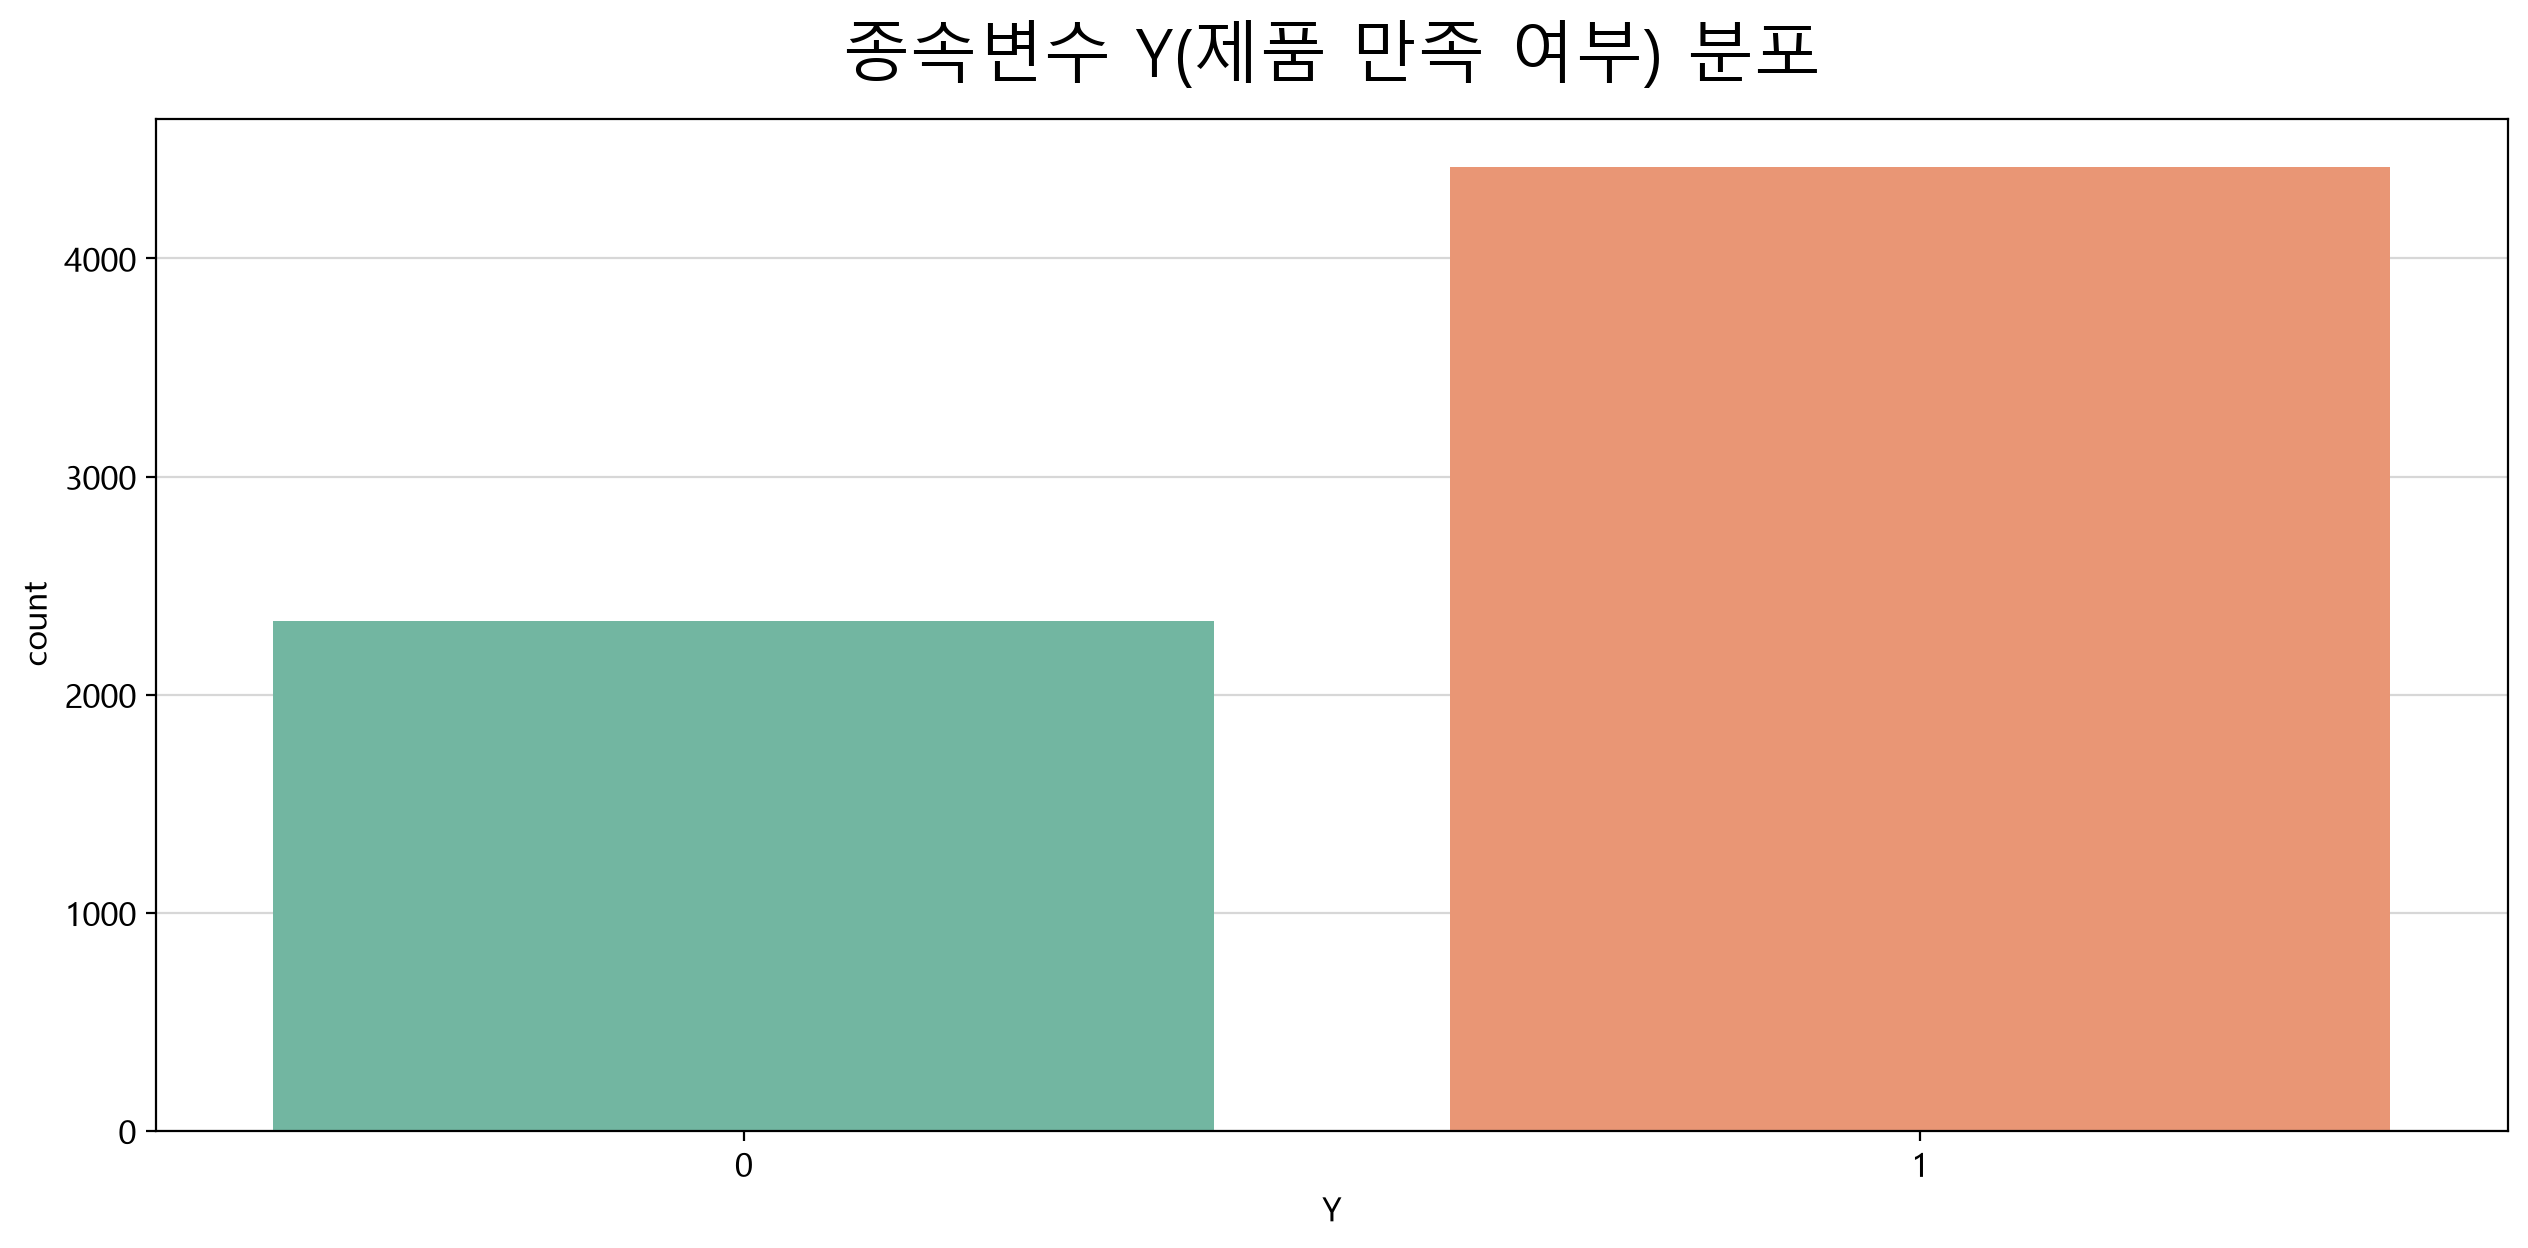

,빈도,비율
Y,,
1,4420,0.654233
0,2336,0.345767


In [31]:

my_plot.countplot(
    data=df_eda,
    x=target,
    hue=target,
    palette='Set2',
    title='종속변수 Y(제품 만족 여부) 분포'
)

freq = df_eda[target].value_counts().rename('빈도').to_frame()
freq['비율'] = df_eda[target].value_counts(normalize=True)

display(freq)

[종속변수 Y]
|점검항목|제품 만족도 관찰값|
|--|--|
|범주 수| 2 (0=불만족/ 1=만족)|
|최빈 범주| 만족 4462건(65.5%)|
|최소 범주| 불만족 2351건(34.5%)|
|균형 여부| 약간 불균형(66:35)|

<br>

>- 정확도의 바닥값(baseline)은 62.3%이다. 모두 "만족"이라고만 답하는 게으른 모형도 65.5%를 맞힌다.
>- 즉, 정확도 70%짜리 모형은 좋은 모형이 아니다. 바닥값보다 4.5%p 나은 것에 불과하다.
>- 66:35 정도면 리샘플링 없이 진행하되, 정확도 하나만 보지 말고 재현도·정밀도·AUC를 함께 확인해야 한다.

### 2. 명목형 독립변수 단변량 분석


In [17]:
column_means['국가'] = '리뷰 작성 국가'
column_means['제품_순위'] = '국가별 제품 순위'
column_means['Y'] = '제품 만족 여부'
column_means['보습'] = '보습 속성 언급 여부'
column_means['향'] = '향 속성 언급 여부'
column_means['발림성'] = '발림성 속성 언급 여부'
column_means['자극'] = '자극 속성 언급 여부'
column_means['용기'] = '용기 속성 언급 여부'
column_means['배송'] = '배송 속성 언급 여부'
column_means['기능'] = '기능 속성 언급 여부'
column_means['가격'] = '가격 속성 언급 여부'
column_means['브랜드충성도'] = '브랜드 충성도 언급 여부'
column_means['토픽_언급수'] = '한 리뷰에서 언급된 9개 속성의 개수'

### ▶︎ 국가 (리뷰 작성 국가) 분포

국가,한국,미국,러시아,일본
빈도,1832.000000,1818.000000,1608.000000,1498.000000
비율,0.271166,0.269094,0.238011,0.221729


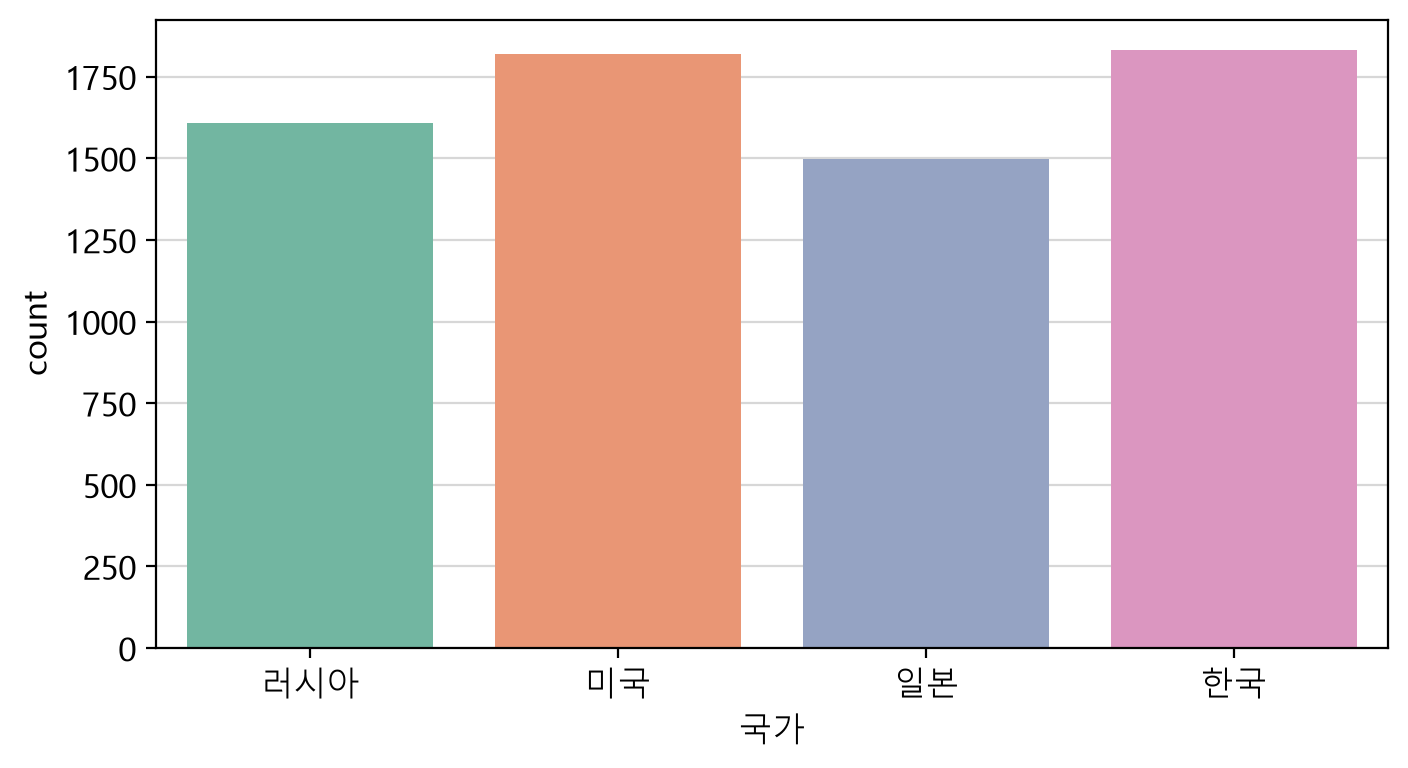

### ▶︎ 제품_순위 (국가별 제품 순위) 분포

제품_순위,8,9,2,1,10,3,5,4,7,6
빈도,741.00000,728.000000,684.000000,681.000000,676.000000,674.000000,657.000000,650.000000,635.000000,630.00000
비율,0.10968,0.107756,0.101243,0.100799,0.100059,0.099763,0.097247,0.096211,0.093991,0.09325


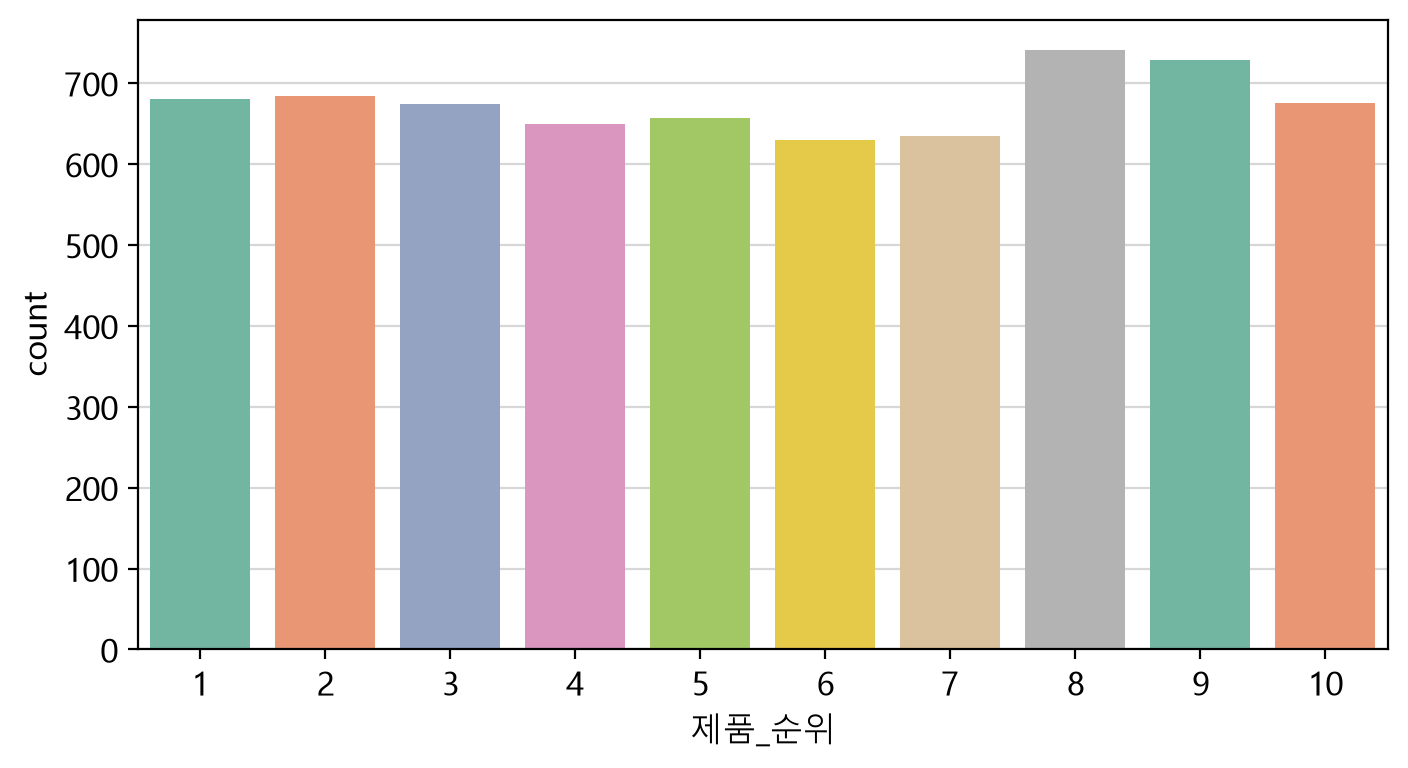

### ▶︎ 보습 (보습 속성 언급 여부) 분포

보습,0,1
빈도,3657.000000,3099.000000
비율,0.541297,0.458703


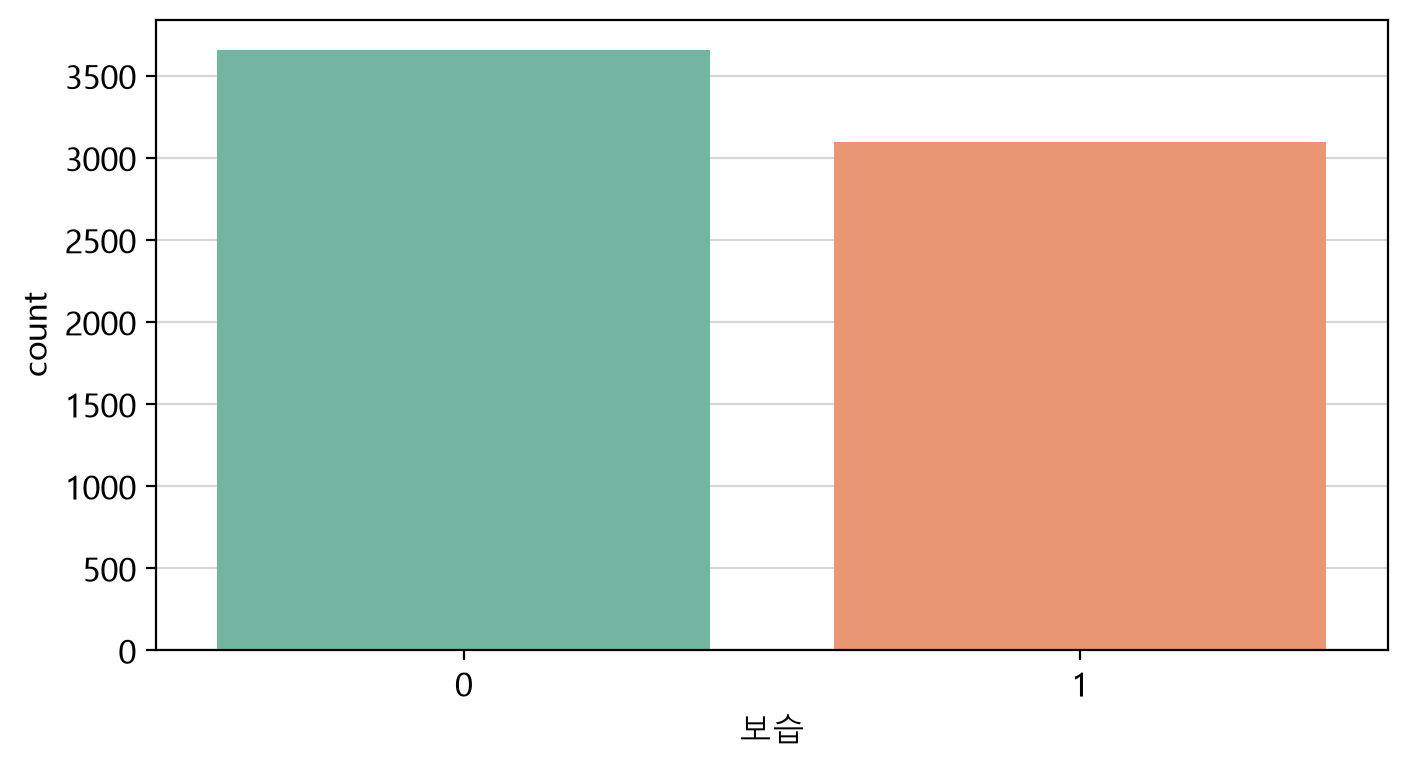

### ▶︎ 향 (향 속성 언급 여부) 분포

향,0,1
빈도,5657.00000,1099.00000
비율,0.83733,0.16267


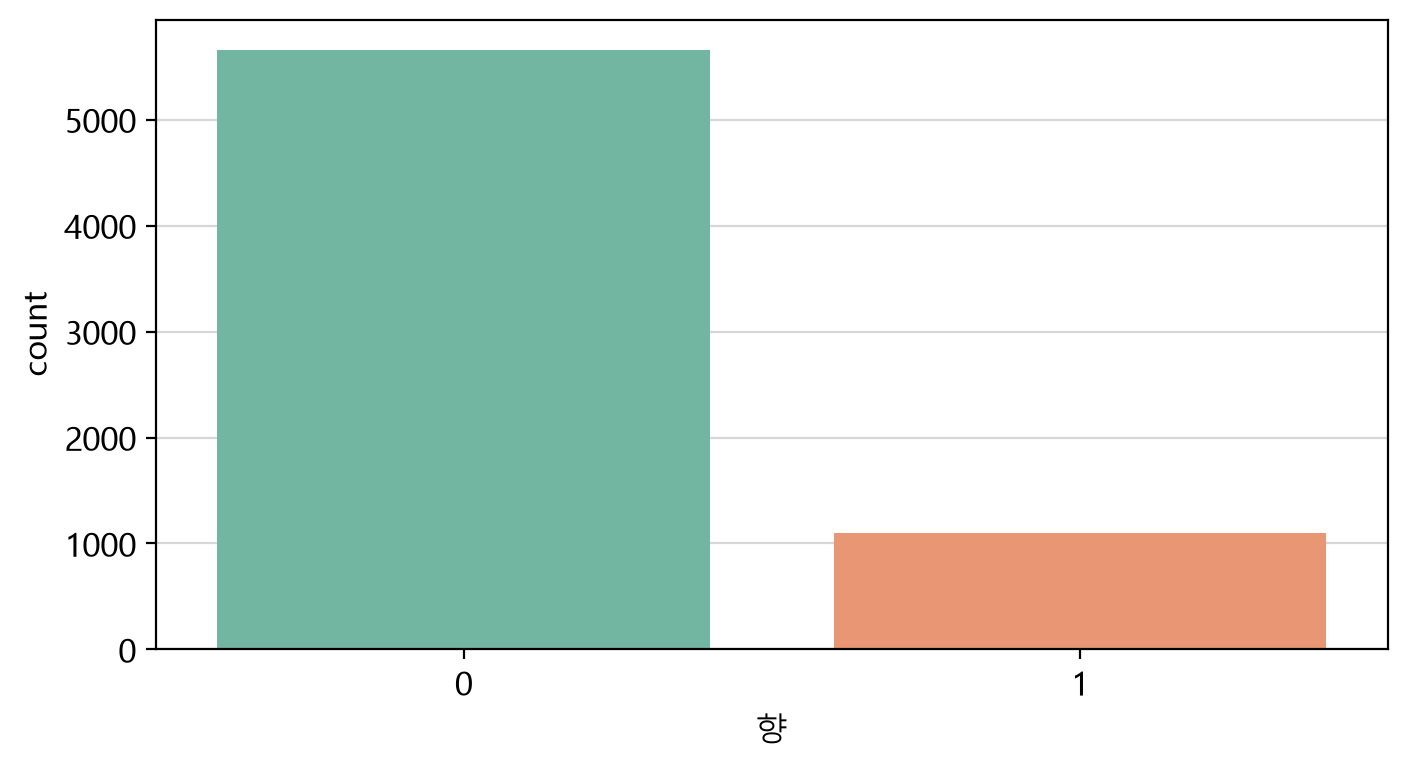

### ▶︎ 발림성 (발림성 속성 언급 여부) 분포

발림성,0,1
빈도,3603.000000,3153.000000
비율,0.533304,0.466696


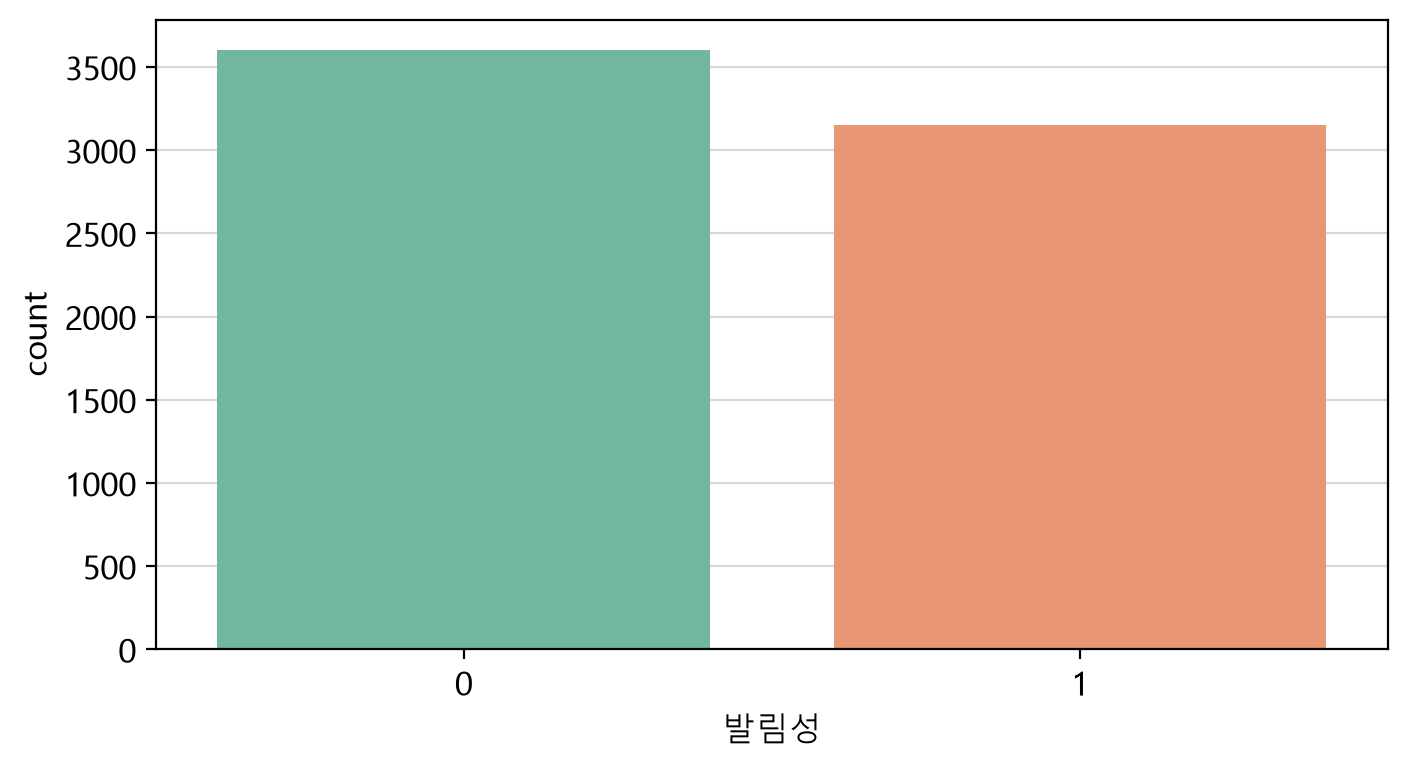

### ▶︎ 자극 (자극 속성 언급 여부) 분포

자극,0,1
빈도,3712.000000,3044.000000
비율,0.549438,0.450562


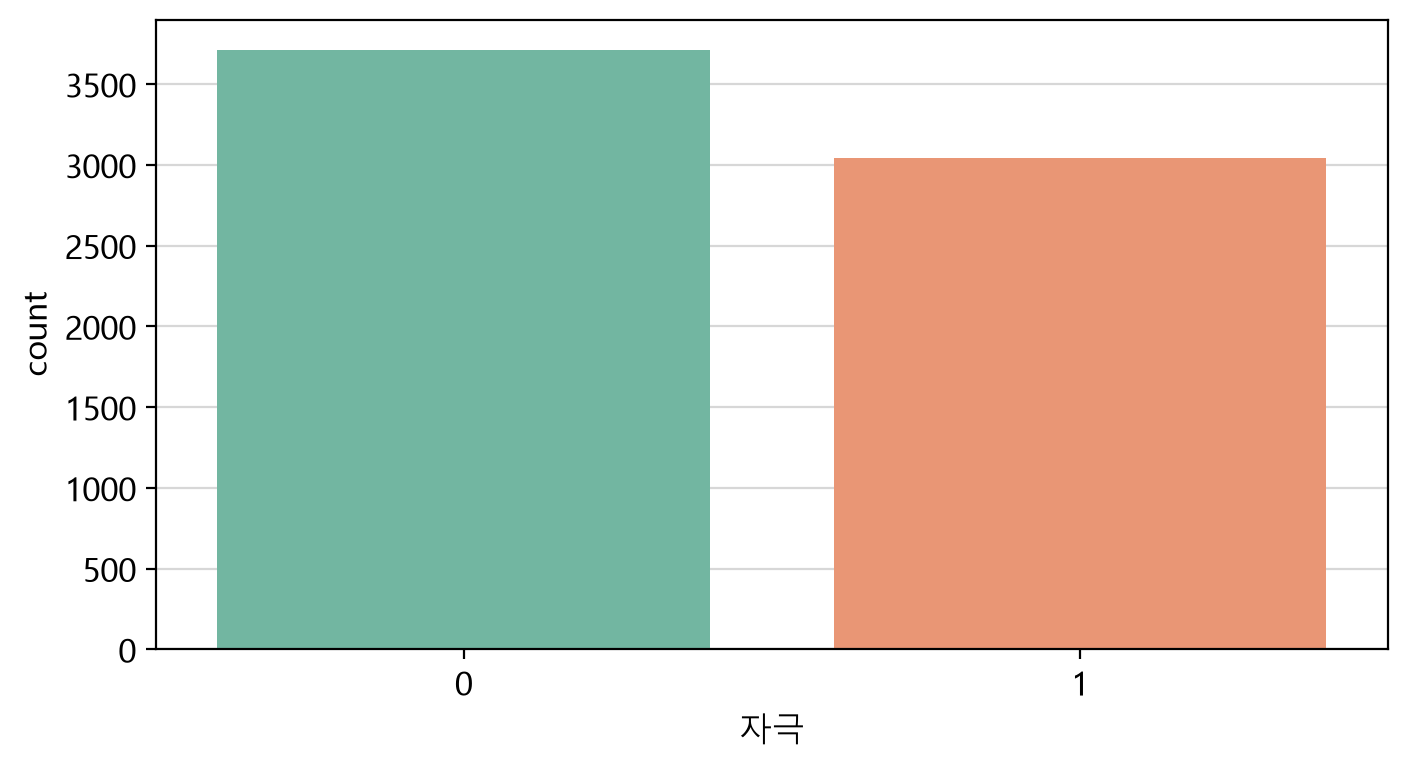

### ▶︎ 용기 (용기 속성 언급 여부) 분포

용기,0,1
빈도,5364.000000,1392.000000
비율,0.793961,0.206039


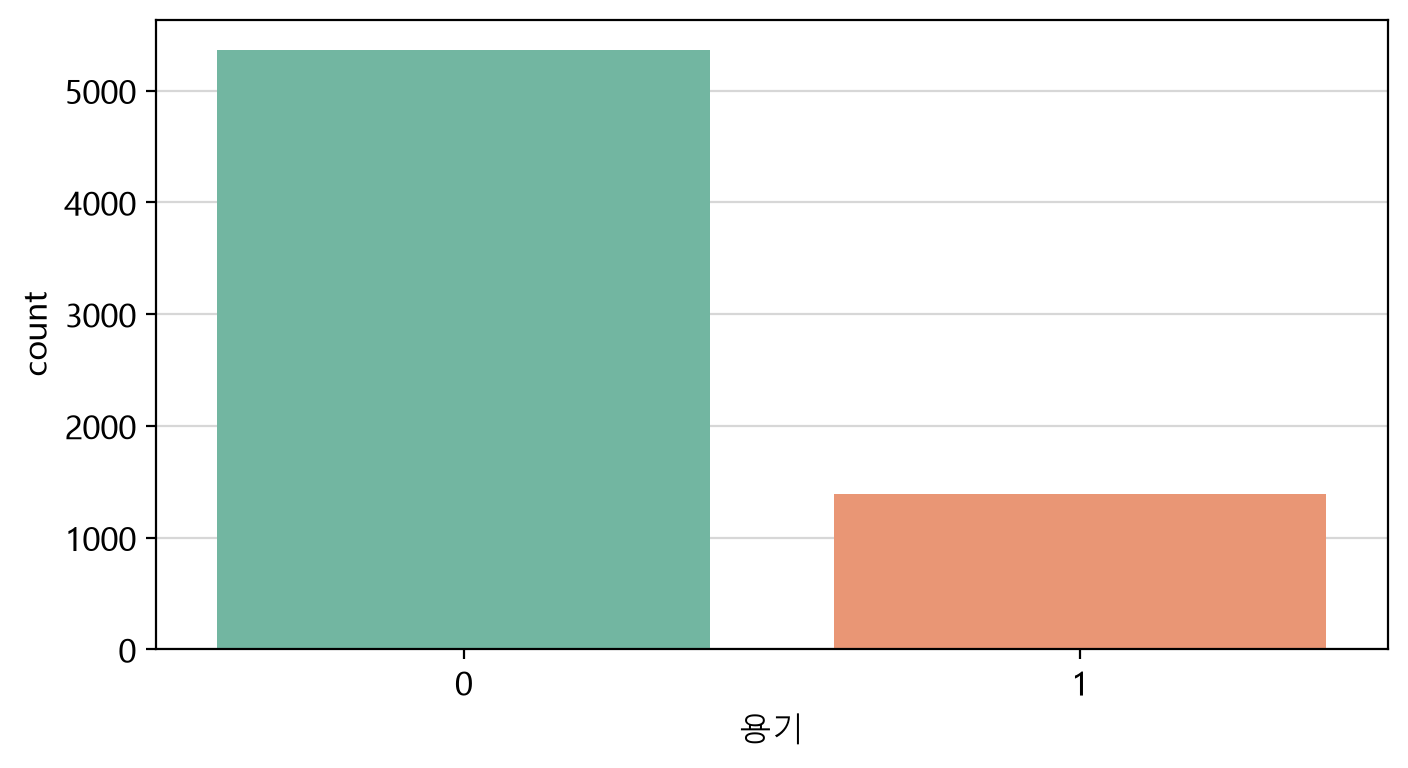

### ▶︎ 배송 (배송 속성 언급 여부) 분포

배송,0,1
빈도,6329.000000,427.000000
비율,0.936797,0.063203


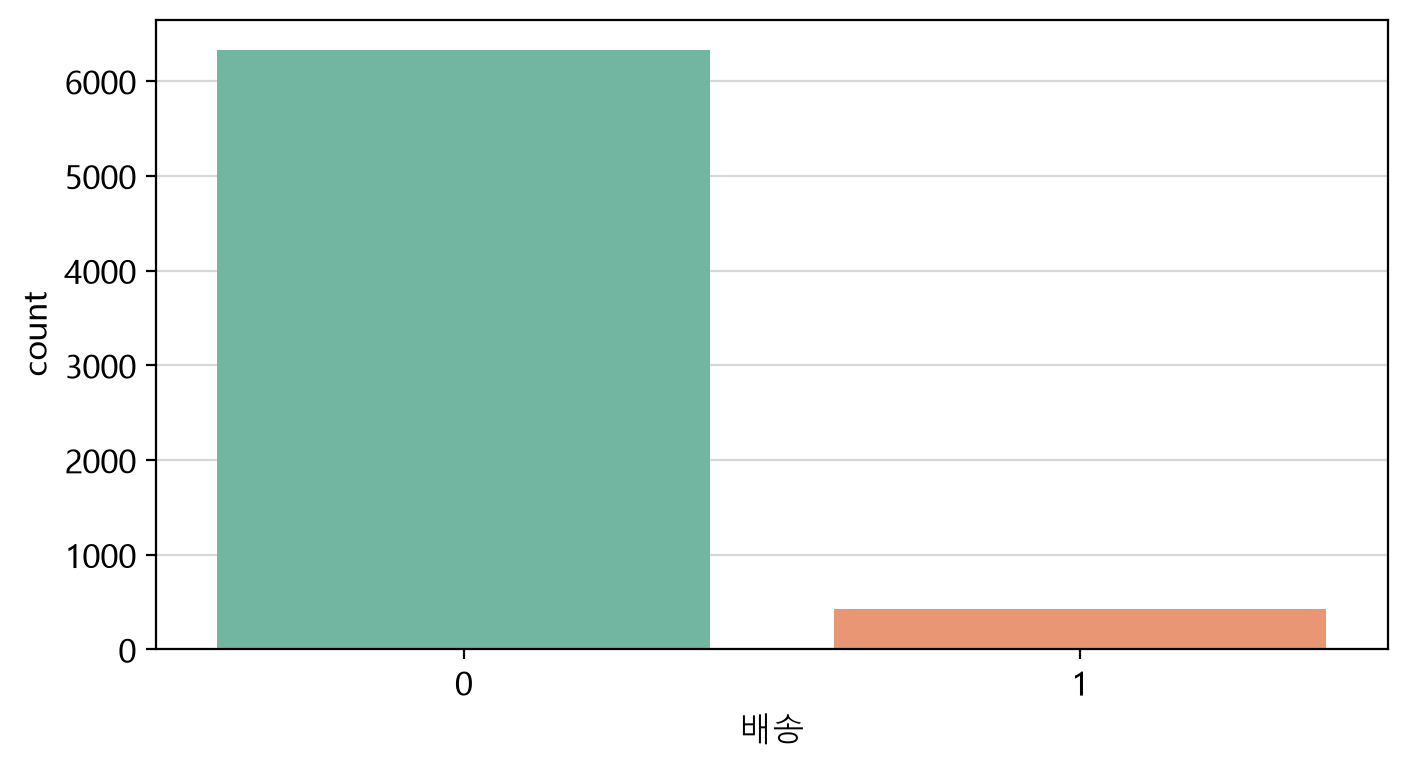

### ▶︎ 기능 (기능 속성 언급 여부) 분포

기능,0,1
빈도,4284.000000,2472.000000
비율,0.634103,0.365897


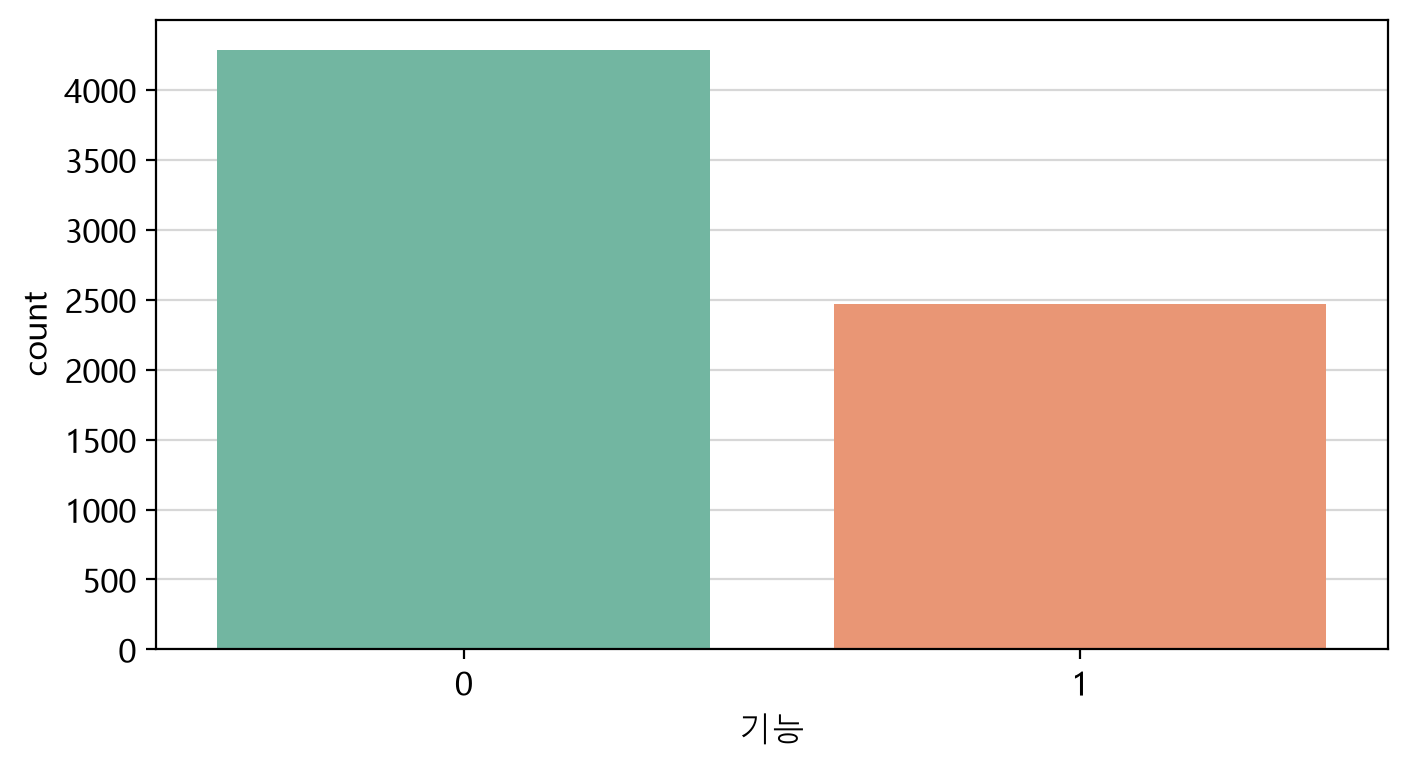

### ▶︎ 가격 (가격 속성 언급 여부) 분포

가격,0,1
빈도,6208.000000,548.000000
비율,0.918887,0.081113


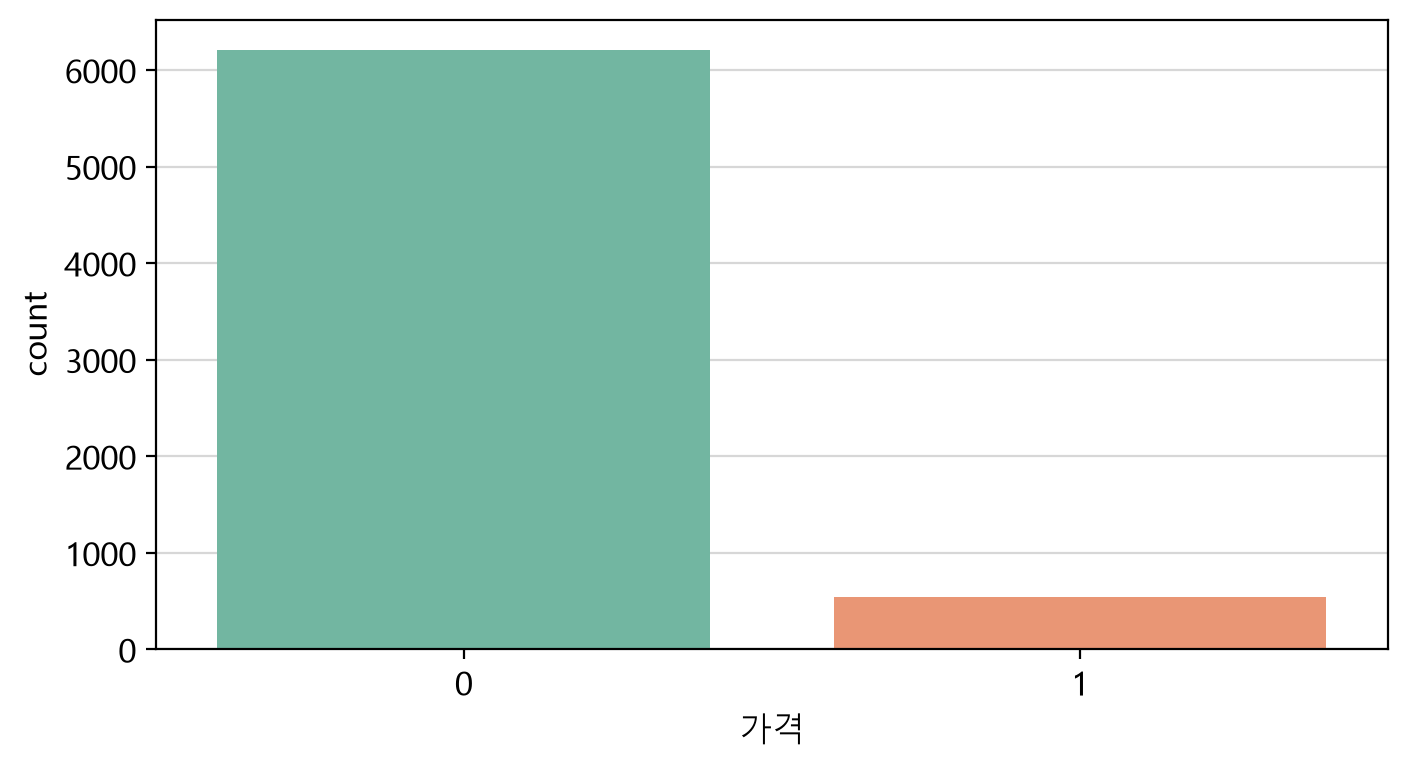

### ▶︎ 브랜드충성도 (브랜드 충성도 언급 여부) 분포

브랜드충성도,0,1
빈도,6033.000000,723.000000
비율,0.892984,0.107016


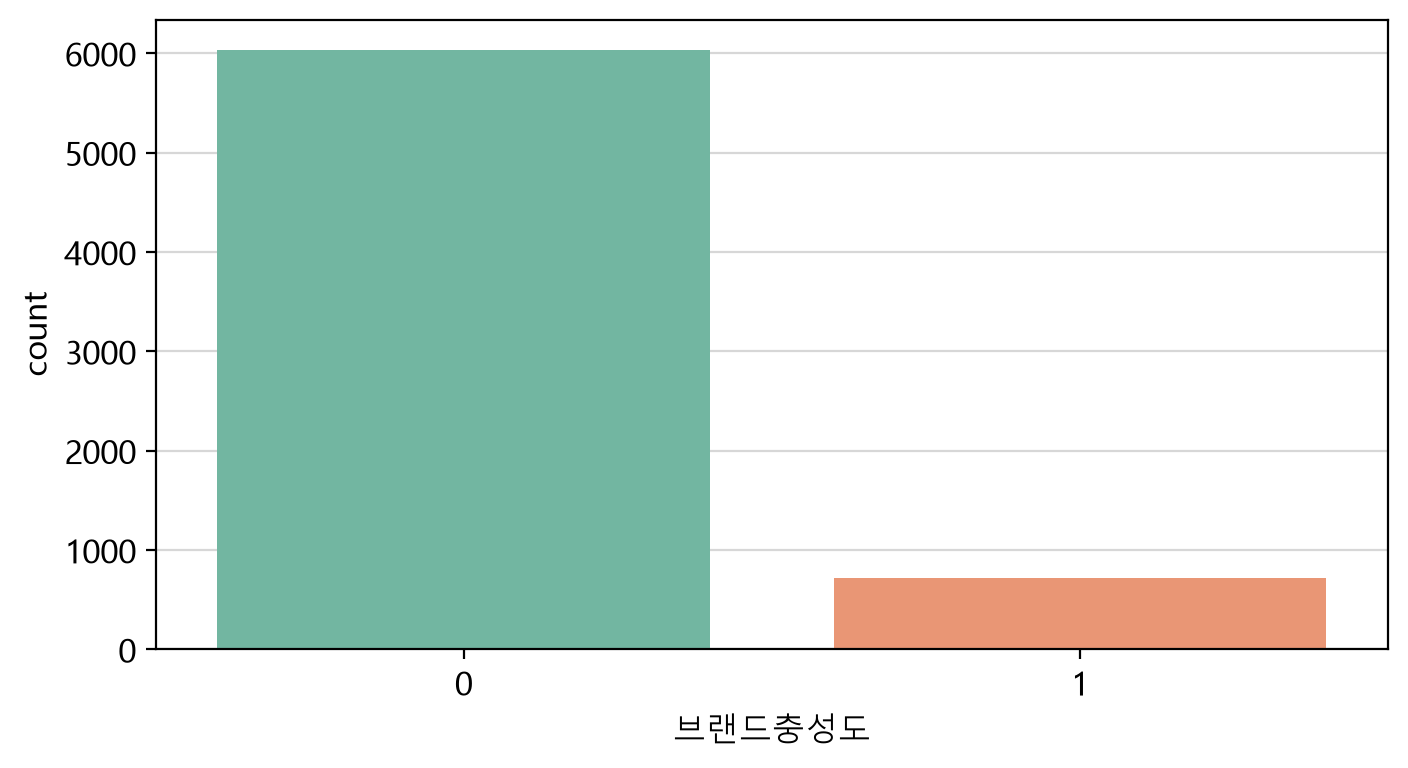

In [32]:
for n in nominal_cols:
    display(Markdown(f"### ▶︎ {n} ({column_means[n]}) 분포"))

    freq = df_eda[n].value_counts().rename('빈도').to_frame()
    freq['비율'] = df_eda[n].value_counts(normalize=True)

    display(freq.T)

    my_plot.countplot(
        data=df_eda,
        x=n,
        hue=n,
        palette='Set2',
        width=720,
        height=400
    )

## 2. 명목형 독립변수 단변량 분석

[국가]
>- 범주분포 : 한국 1850 (27.2%), 미국 1832 (26.9%), 러시아 1627 (23.9%), 일본 1504 (22.1%) 
>- 판단 : 어느 한 국가에 쏠리지 않고 모든 국가의 표본이 고르게 확보되었으므로, 국가별 비교 분석을 진행하기에 충분한 데이터 신뢰도를 갖추고 있다.


[제품순위]
>- 범주분포 : 8위 747 (11%), 9위 734 (10.8%), 2위 688 (10.1%), 1위 683 (10%), 10위 683 (10%), 3위 680 (9.9%), 5위 663 (9.7%), 4위 655 (9.6%), 7위 647 (9.5%), 6위 633 (9.3%)
>- 판단 : 10개 범주의 10% 안팎으로 아주 고르게 분포되어 있어, 특정 제품으로 쏠리는 편향(Bias) 문제가 없는 이상적인 형태이다.


[보습]
>- 범주수 2 : 0 = 미언급, 1= 언급
>- 범주분포 : 미언급 3714(54.5%), 언급 3099 (45.5%)
>- 판단 : 56:46로, 거의 5대 5에 가까운 이상적인 이진 분포이다.


[향]
>- 범주수 2 : 0 = 미언급, 1= 언급
>- 범주분포 : 미언급 5714 (83.9%), 언급 1099 (16.1%)
>- 판단 : '미언급'이 약 84%를 차지하는 심한 클래스 불균형상태이다. 대부분의 리뷰가 향에 대해 특별히 언급하지 않았음을 의미한다.


[발림성]
>- 범주수 2 : 0 = 미언급, 1= 언급
>- 범주분포 : 미언급 3660(53.7%), 언급 3153 (46.3%)
>- 판단 : 54:46로, 거의 5대 5에 가까운 이상적인 이진 분포이다.

[자극]
>- 범주수 2 : 0 = 미언급, 1 = 언급
>- 범주분포 : 미언급 3,458(50.8%), 언급 3,355(49.2%)
>- 판단 : 51:49로, 거의 5대 5에 가까운 이상적인 이진 분포이다.

[용기]
>- 범주수 2 : 0 = 미언급, 1 = 언급
>- 범주분포 : 미언급 5,421(79.6%), 언급 1,392(20.4%)
>- 판단 : 80:20으로, 언급 범주가 소수인 불균형 분포이다.

[배송]
>- 범주수 2 : 0 = 미언급, 1 = 언급
>- 범주분포 : 미언급 6,386(93.7%), 언급 427(6.3%)
>- 판단 : 94:6으로, 언급 범주가 극소수인 심한 불균형 분포이다.

[기능]
>- 범주수 2 : 0 = 미언급, 1 = 언급
>- 범주분포 : 미언급 3,897(57.2%), 언급 2,916(42.8%)
>- 판단 : 57:43으로, 5대 5에 근접한 비교적 균형적인 분포이다.

[가격]
>- 범주수 2 : 0 = 미언급, 1 = 언급
>- 범주분포 : 미언급 6,265(92.0%), 언급 548(8.0%)
>- 판단 : 92:8로, 언급 범주가 극소수인 심한 불균형 분포이다.

[브랜드 충성도]
>- 범주수 2 : 0 = 미언급, 1 = 언급
>- 범주분포 : 미언급 5,892(86.5%), 언급 921(13.5%)
>- 판단 : 87:14로, 언급 범주가 소수인 불균형 분포이다.

## #08. 이변량 분석
### 1. 명목형 독립변수 → Y 교차분석

#### ▶︎ 국가 → Y

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
국가,Y,Chi-square test of independence,670.5102,3,0.0,True,0.315,Moderate,517.96,True


Y,0,1
국가,,
러시아,0.166045,0.833955
미국,0.466447,0.533553
일본,0.204272,0.795728
한국,0.499454,0.500546


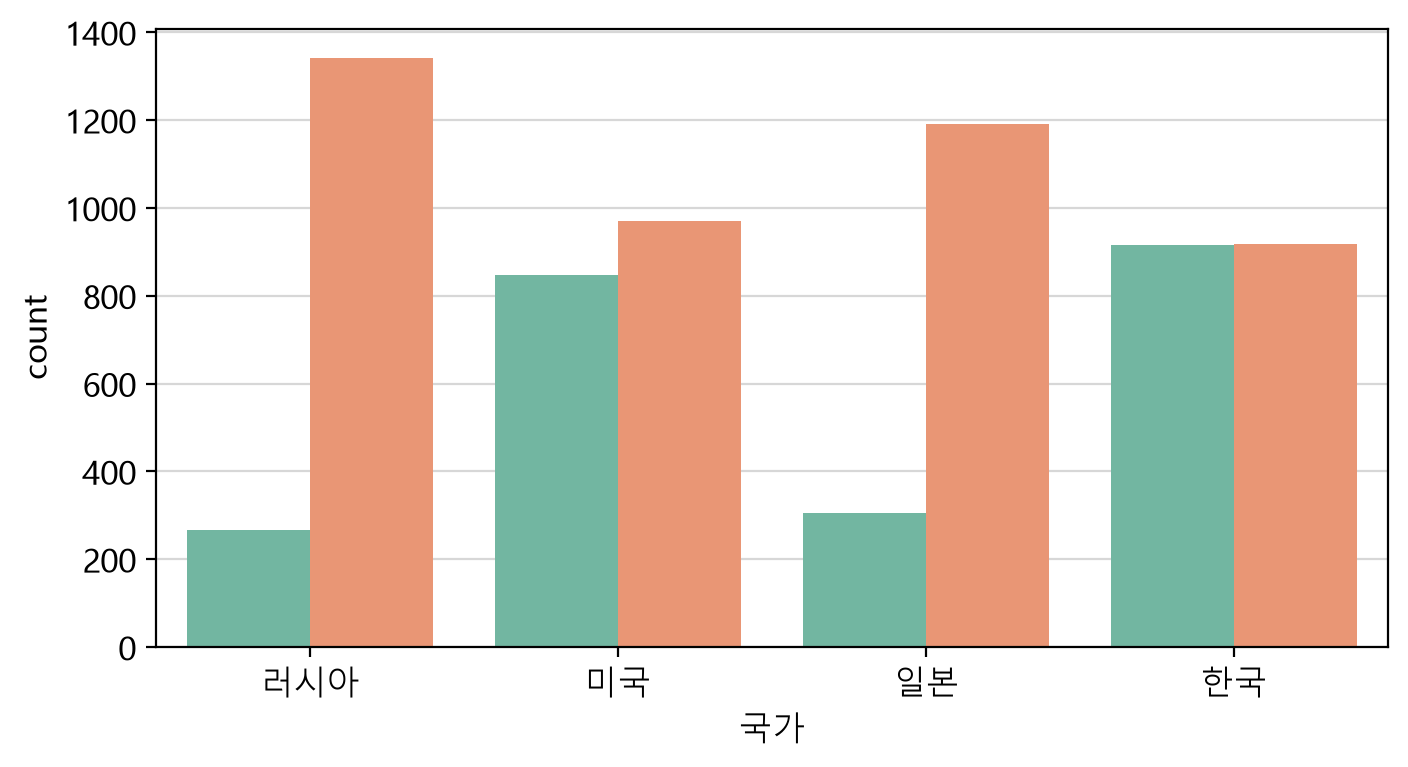

#### ▶︎ 제품_순위 → Y

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
제품_순위,Y,Chi-square test of independence,65.483,9,0.0,True,0.0985,Negligible,217.83,True


Y,0,1
제품_순위,,
1,0.356828,0.643172
2,0.343567,0.656433
3,0.329377,0.670623
4,0.333846,0.666154
5,0.371385,0.628615
6,0.307937,0.692063
7,0.233071,0.766929
8,0.419703,0.580297
9,0.377747,0.622253


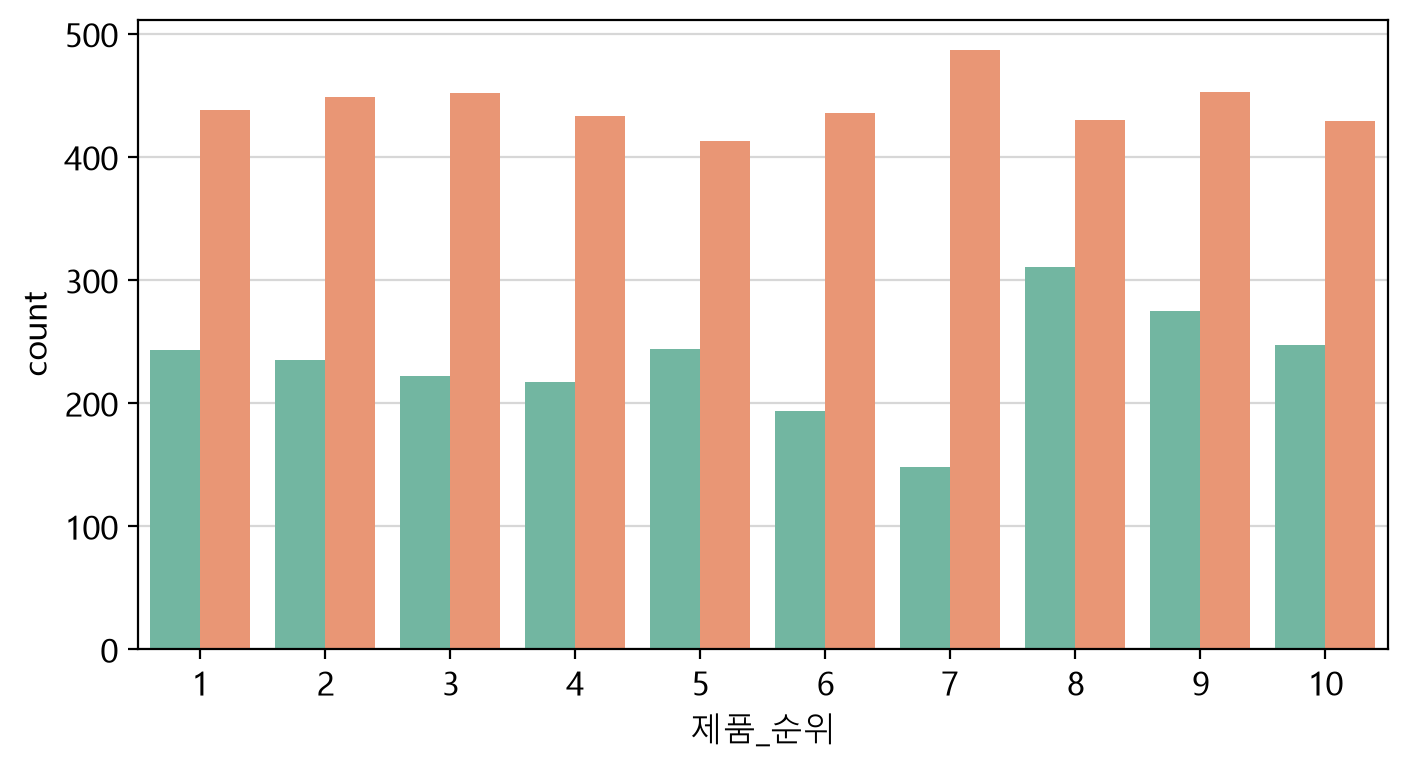

#### ▶︎ 보습 → Y

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
보습,Y,Chi-square test of independence,69.1869,1,0.0,True,0.1012,Weak,1071.53,True


Y,0,1
보습,,
0,0.390211,0.609789
1,0.293320,0.706680


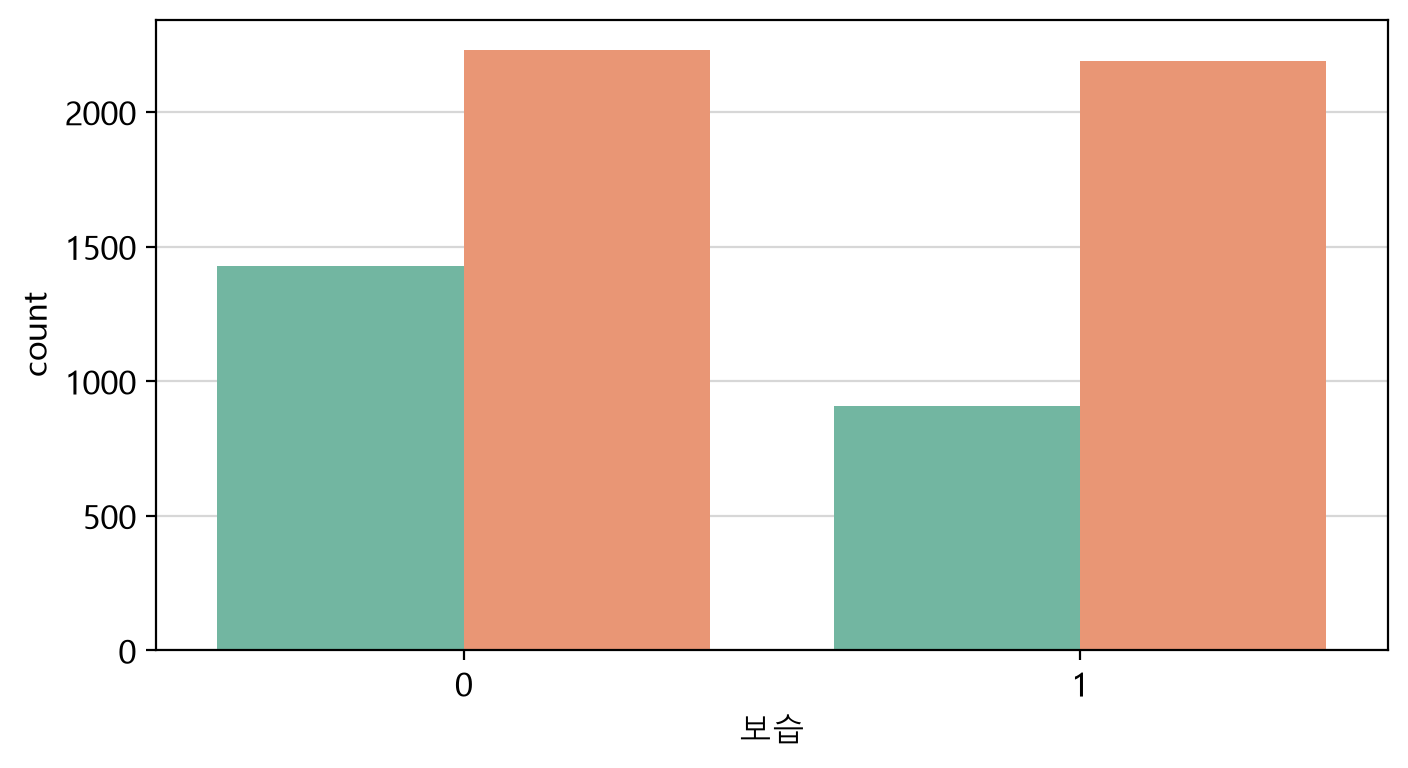

#### ▶︎ 향 → Y

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
향,Y,Chi-square test of independence,101.6955,1,0.0,True,0.1227,Weak,380.0,True


Y,0,1
향,,
0,0.371575,0.628425
1,0.212921,0.787079


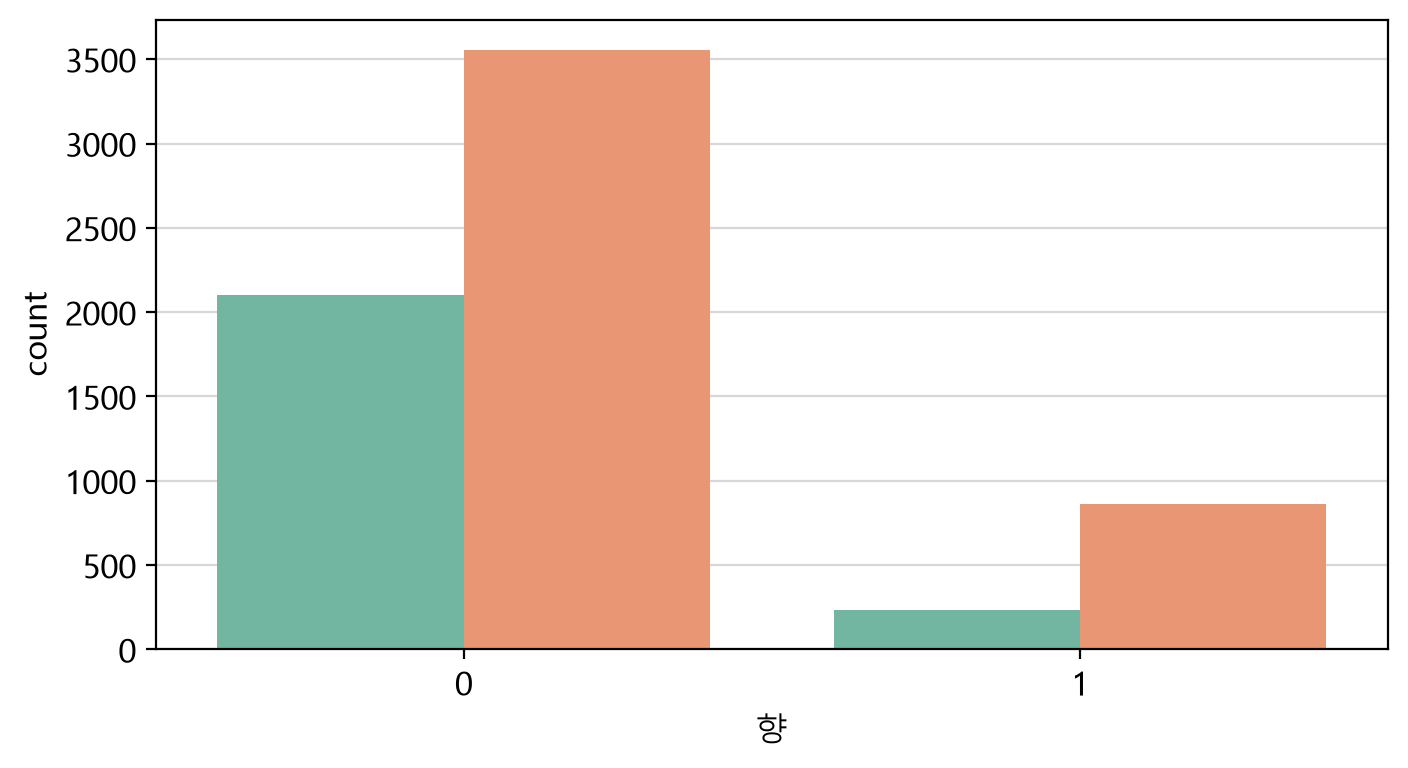

#### ▶︎ 발림성 → Y

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
발림성,Y,Chi-square test of independence,40.8823,1,0.0,True,0.0778,Negligible,1090.2,True


Y,0,1
발림성,,
0,0.380516,0.619484
1,0.306058,0.693942


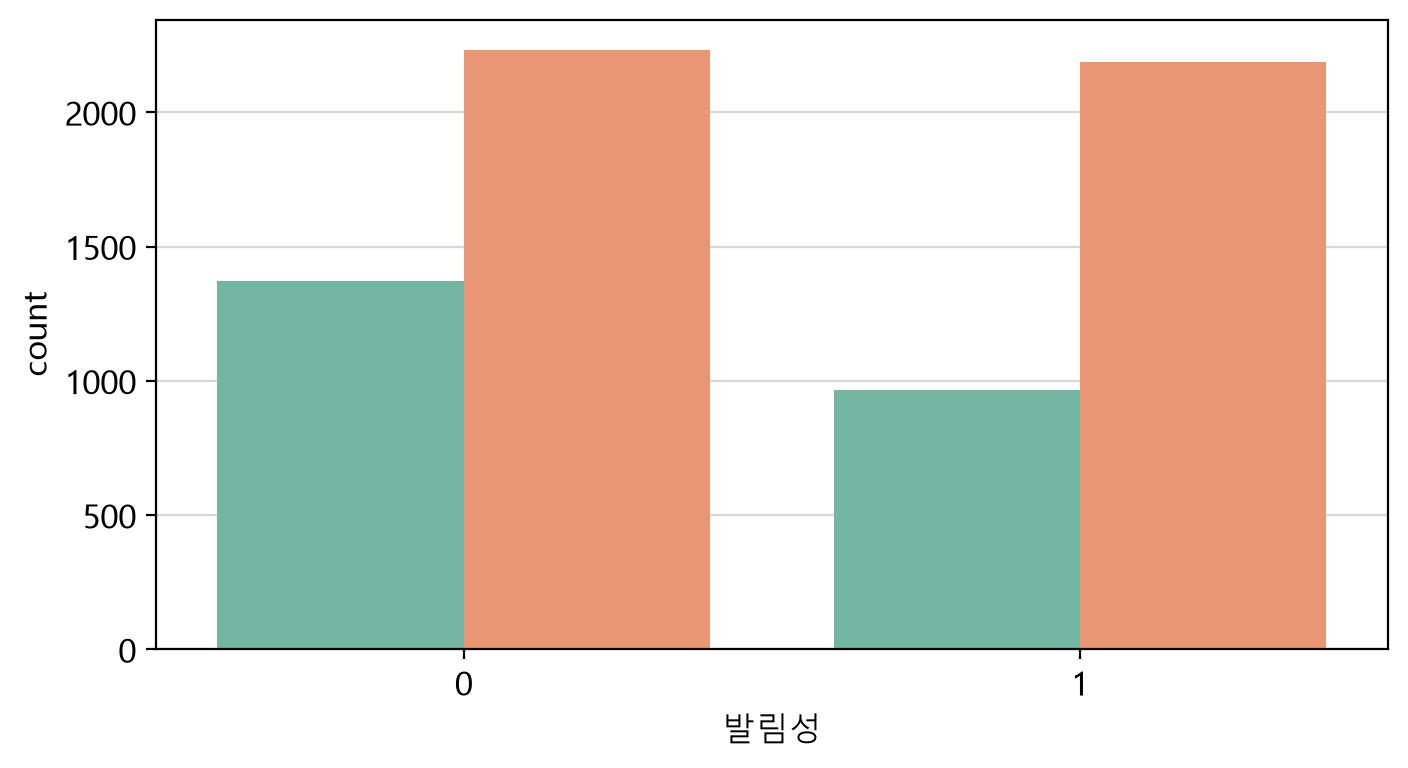

#### ▶︎ 자극 → Y

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
자극,Y,Chi-square test of independence,573.9408,1,0.0,True,0.2915,Weak,1052.51,True


Y,0,1
자극,,
0,0.220097,0.779903
1,0.499014,0.500986


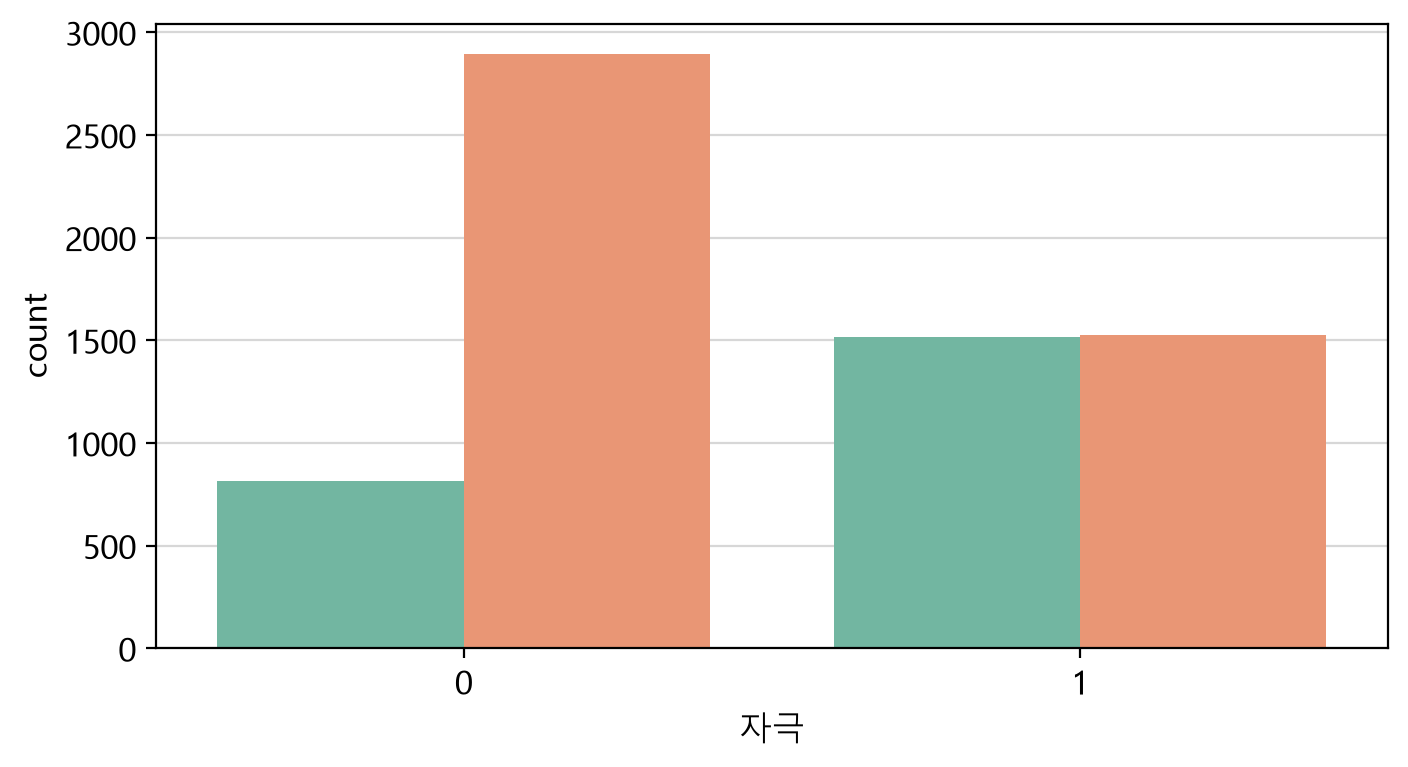

#### ▶︎ 용기 → Y

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
용기,Y,Chi-square test of independence,18.9372,1,0.000014,True,0.0529,Negligible,481.31,True


Y,0,1
용기,,
0,0.358688,0.641312
1,0.295977,0.704023


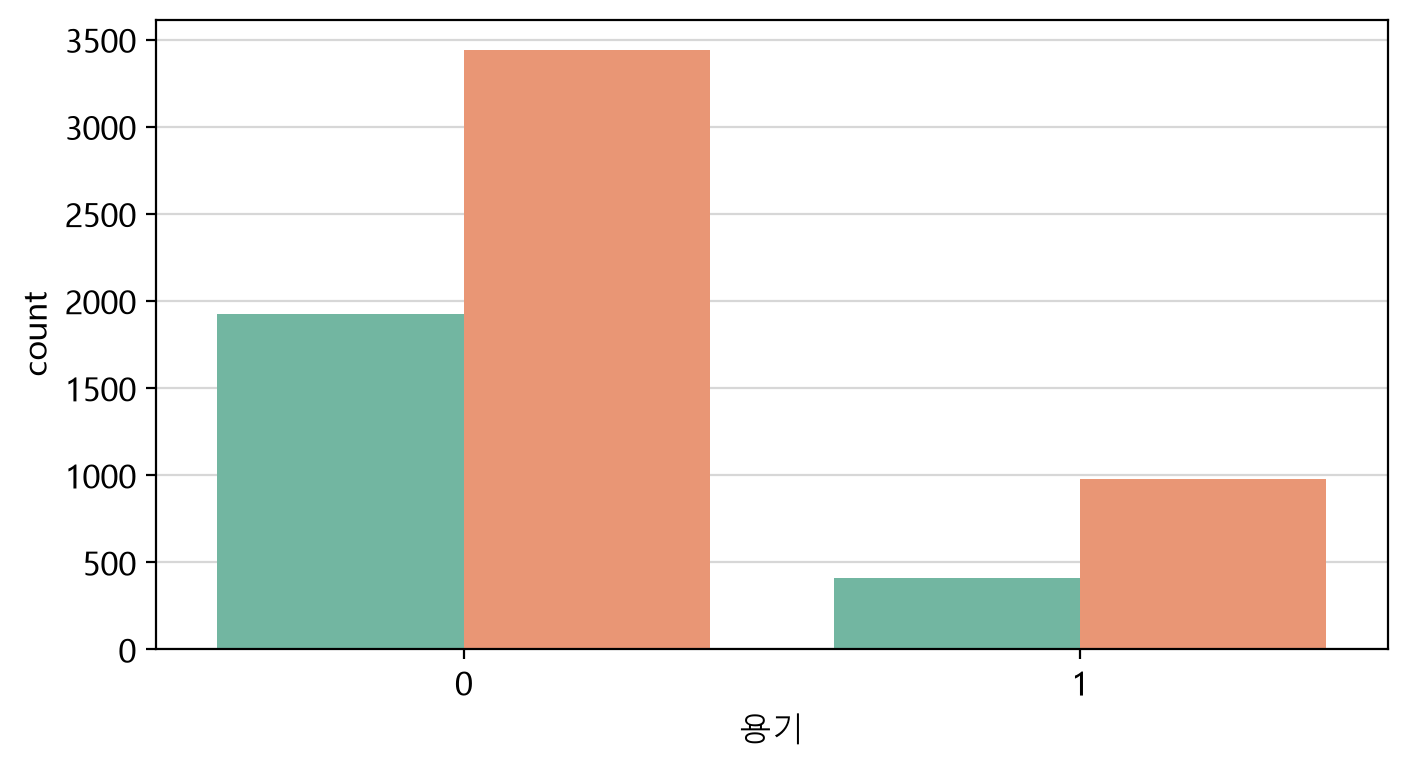

#### ▶︎ 배송 → Y

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
배송,Y,Chi-square test of independence,49.3984,1,0.0,True,0.0855,Negligible,147.64,True


Y,0,1
배송,,
0,0.335124,0.664876
1,0.503513,0.496487


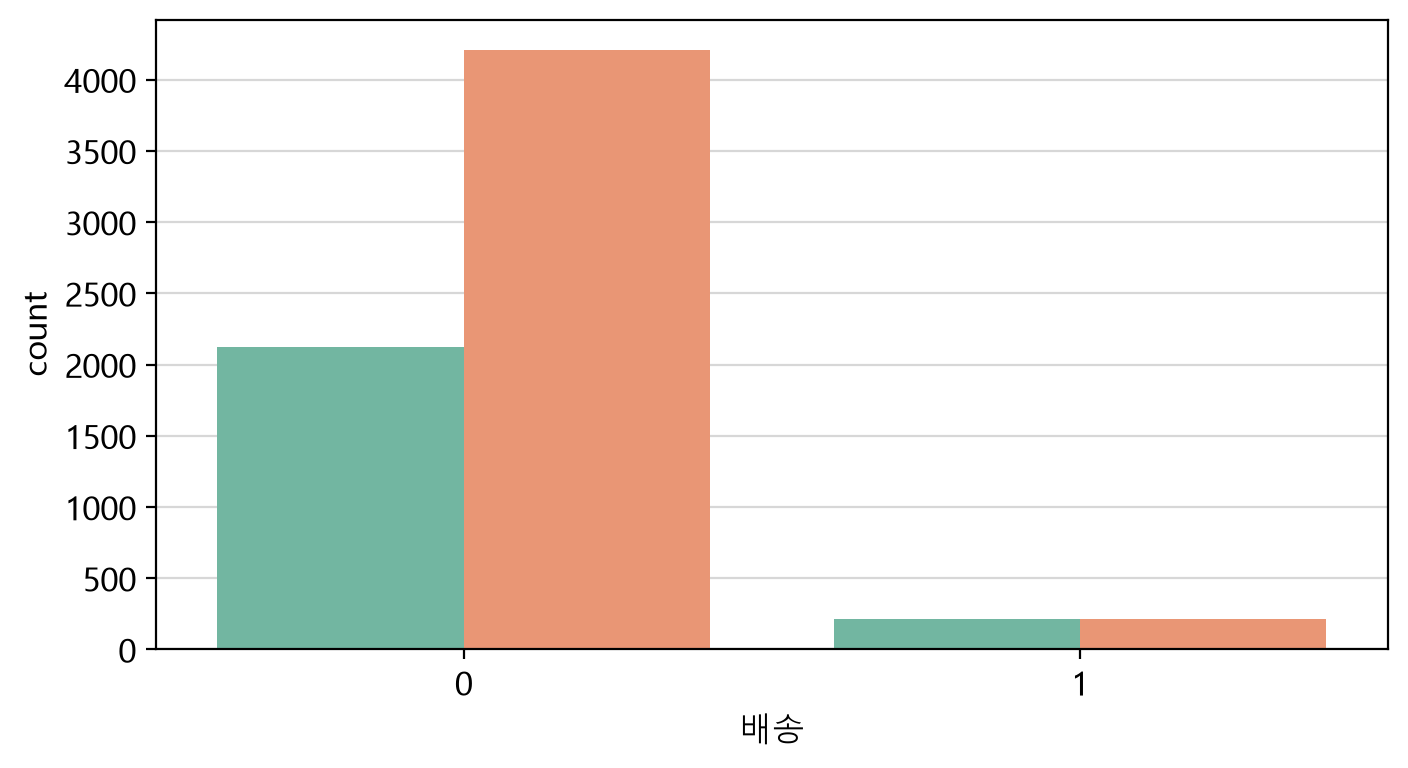

#### ▶︎ 기능 → Y

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
기능,Y,Chi-square test of independence,254.214,1,0.0,True,0.194,Weak,854.74,True


Y,0,1
기능,,
0,0.415966,0.584034
1,0.224110,0.775890


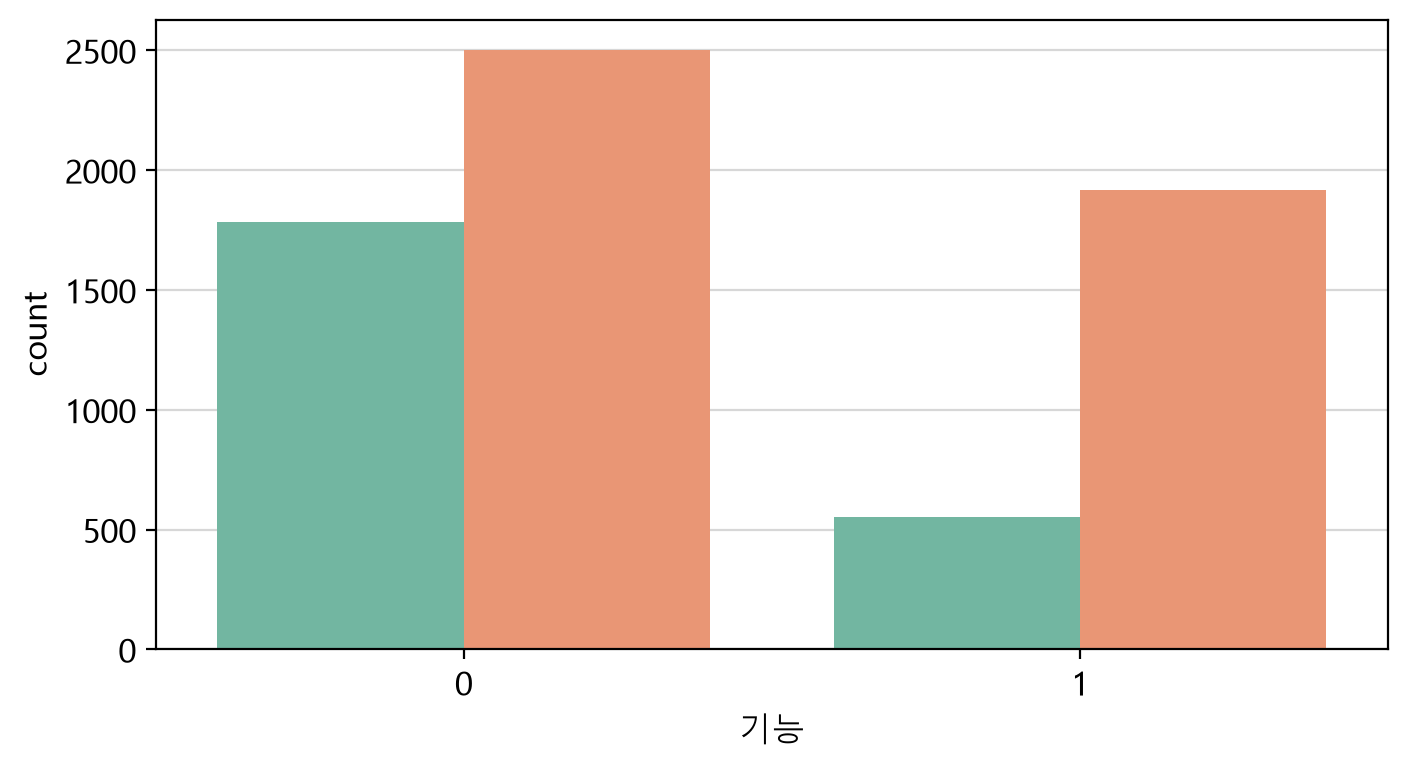

#### ▶︎ 가격 → Y

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
가격,Y,Chi-square test of independence,13.3392,1,0.00026,True,0.0444,Negligible,189.48,True


Y,0,1
가격,,
0,0.352126,0.647874
1,0.273723,0.726277


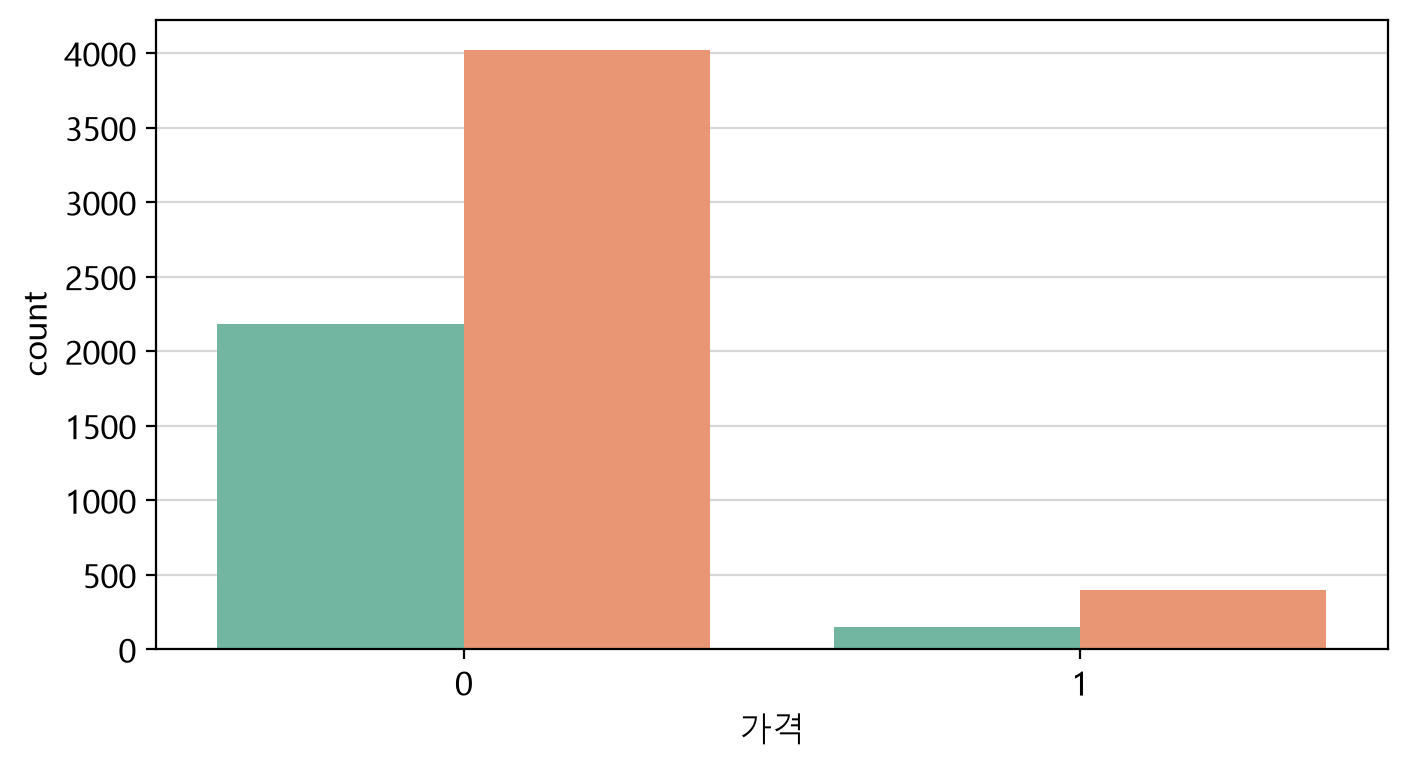

#### ▶︎ 브랜드충성도 → Y

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
브랜드충성도,Y,Chi-square test of independence,32.118,1,0.0,True,0.0689,Negligible,249.99,True


Y,0,1
브랜드충성도,,
0,0.357202,0.642798
1,0.250346,0.749654


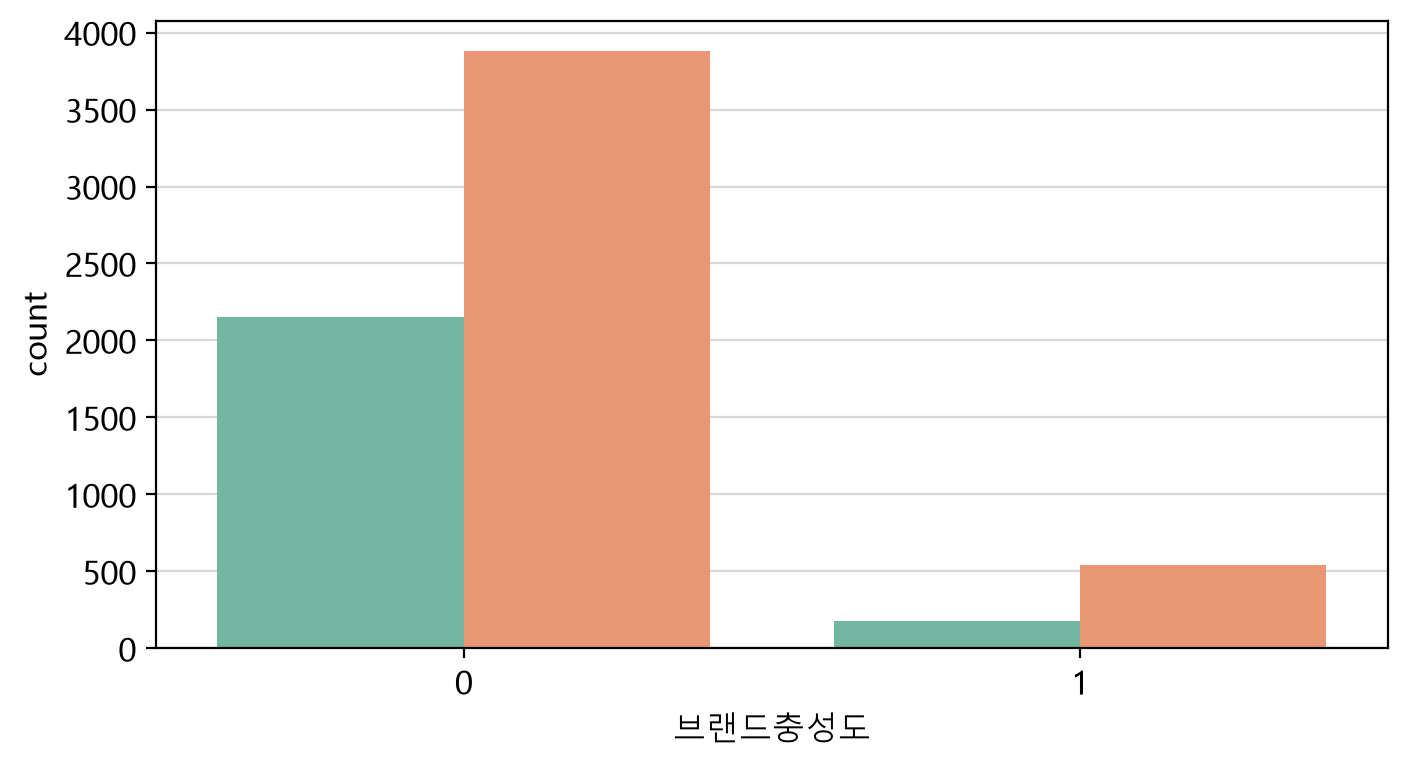

In [30]:

for n in nominal_cols:

    print()
    display(Markdown(f"#### ▶︎ {n} → {target}"))

    # 카이제곱 독립성 검정
    display(
        my_stats.chi2_independence(
            df_eda,
            x=n,
            y=target,
            plot=False
        )
    )

    # 범주별 Y 비율
    rate = (
        df_eda
        .groupby(n, observed=True)[target]
        .value_counts(normalize=True)
        .unstack()
    )

    display(rate)

    my_plot.countplot(
        data=df_eda,
        x=n,
        hue=target,
        palette='Set2',
        width=720,
        height=400
    )

### 2. 국가별 속성 언급 패턴


In [23]:

for topic in topic_cols:

    display(Markdown(f"#### ▶︎ 국가 → {topic}"))

    # 국가와 해당 속성 간 독립성 검정
    display(
        my_stats.chi2_independence(
            df_eda,
            x='국가',
            y=topic,
            plot=False
        )
    )

    # 국가별 0/1 비율
    rate = pd.crosstab(
        df_eda['국가'],
        df_eda[topic],
        normalize='index'
    ) * 100

    display(rate.round(2))

#### ▶︎ 국가 → 보습

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
국가,보습,Chi-square test of independence,472.4152,3,0.0,True,0.2644,Weak,687.14,True


보습,0,1
국가,,
러시아,76.06,23.94
미국,42.96,57.04
일본,55.87,44.13
한국,44.54,55.46


#### ▶︎ 국가 → 향

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
국가,향,Chi-square test of independence,917.7078,3,0.0,True,0.3686,Moderate,243.68,True


...

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
국가,가격,Chi-square test of independence,69.0714,3,0.0,True,0.1011,Weak,121.51,True


가격,0,1
국가,,
러시아,95.27,4.73
미국,92.85,7.15
일본,87.32,12.68
한국,91.70,8.30


#### ▶︎ 국가 → 브랜드충성도

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
국가,브랜드충성도,Chi-square test of independence,219.0939,3,0.0,True,0.1801,Weak,160.31,True


브랜드충성도,0,1
국가,,
러시아,92.23,7.77
미국,91.64,8.36
일본,78.91,21.09
한국,92.90,7.10


### 3. 국가 × 속성 언급률

- 전체 언급률: 해당 속성을 언급한 리뷰 수 ÷ 전체 리뷰 수 (예: 향 1,099 ÷ 6,756 = 16.3%)
- 국가별 언급률: 국가마다 해당 속성을 언급한 리뷰의 비율(%)
- 국가 간 차이: 국가 × 속성 언급 여부의 카이제곱 독립성 검정 — Cramér's V가 0이면 국가 간 차이가 없고, 클수록 국가마다 언급률이 크게 다름


In [24]:
# ── 국가 × 속성 언급률 ──
# 속성은 범주형(category)이라 계산용으로만 0/1 숫자로 변환
topic_num = df_eda[topic_cols].astype(int)

# 1) 전체 언급률 = 언급 리뷰 수 ÷ 전체 리뷰 수
display(pd.DataFrame({
    '언급 리뷰 수': topic_num.sum(),
    '전체 리뷰 수': len(df_eda),
    '전체 언급률(%)': topic_num.mean().mul(100).round(1),
}).T.style.format('{:g}'))

# 2) 국가별 언급률(%)
display(topic_num.groupby(df_eda['국가'], observed=True).mean().mul(100).round(1))

# 3) 국가 간 차이 — 국가 × 속성 독립성 검정 (Cramér's V)
country_chi2 = pd.concat([
    my_stats.chi2_independence(df_eda, x='국가', y=t, plot=False) for t in topic_cols
])
display(country_chi2[['chi2', 'dof', 'p-value', 'effect(V)', 'strength']])

,보습,향,발림성,자극,용기,배송,기능,가격,브랜드충성도
언급 리뷰 수,3099,1099,3153,3044,1392,427,2472,548,723
전체 리뷰 수,6756,6756,6756,6756,6756,6756,6756,6756,6756
전체 언급률(%),45.9,16.3,46.7,45.1,20.6,6.3,36.6,8.1,10.7


,보습,향,발림성,자극,용기,배송,기능,가격,브랜드충성도
국가,,,,,,,,,
러시아,23.9,39.2,47.0,14.9,35.0,10.8,47.8,4.7,7.8
미국,57.0,14.8,46.4,55.6,14.8,3.4,38.0,7.2,8.4
일본,44.1,10.3,42.3,43.5,22.1,6.5,44.4,12.7,21.1
한국,55.5,2.5,50.3,62.4,12.6,5.1,19.0,8.3,7.1


chi2  dof   p-value  effect(V)    strength
row col                                                   
국가  보습      472.4152    3  0.000000     0.2644        Weak
    향       917.7078    3  0.000000     0.3686    Moderate
    발림성      21.4223    3  0.000086     0.0563  Negligible
    자극      898.4182    3  0.000000     0.3647    Moderate
    용기      314.3909    3  0.000000     0.2157        Weak
    배송       85.9225    3  0.000000     0.1128        Weak
    기능      371.8036    3  0.000000     0.2346        Weak
    가격       69.0714    3  0.000000     0.1011        Weak
    브랜드충성도  219.0939    3  0.000000     0.1801        Weak

# 08. 이변량 분석

## 1. 명목형 독립변수와 Y의 관계

종속변수 `Y`와 각 명목형 독립변수 간의 관계를 확인하기 위해 교차분석과 카이제곱 독립성 검정을 수행하였다.

분석 대상 변수는 다음과 같다.

- 국가
- 제품_순위
- 보습
- 향
- 발림성
- 자극
- 용기
- 배송
- 기능
- 가격
- 브랜드충성도

각 변수의 범주별로 `Y=0`과 `Y=1`의 비율을 비교하고, 카이제곱 검정을 통해 두 변수 간 통계적으로 유의한 관련성이 존재하는지 확인하였다.

### 판단 기준

- `p-value < 0.05` : 해당 독립변수와 `Y` 사이에 통계적으로 유의한 관련성이 있다고 판단한다.
- `p-value ≥ 0.05` : 해당 독립변수와 `Y` 사이의 관련성이 통계적으로 유의하지 않다고 판단한다.

또한 단순히 유의확률만 확인하지 않고, 각 범주에서 `Y=0`과 `Y=1`의 비율이 실제로 어떻게 달라지는지도 함께 확인한다.

이 분석 결과를 바탕으로 이후 다변량 분석 및 최종 변수 선택에 활용한다.

## #09. 다변량 분석
### 1. 속성 간 상관관계 확인
- 목적: 9개 속성을 로지스틱 회귀에 함께 투입하기 전에, 속성끼리 같은 정보를 중복해서 담고 있는지 확인
- 방법: 0/1 속성 간 Pearson 상관계수 (0/1 변수끼리는 φ계수와 같음) · 36쌍
- 판단 기준: |r| > 0.7 강함(제거 검토) · 0.3 초과 중간(주의) · 0.3 이하 약함(중복 아님)
- 출력: ① 상관행렬 ② 쌍별 상관분석 결과 (|r| 큰 순) ③ 변수별 중복 신호 (|r| > 0.3인 쌍 개수)

In [ ]:
from itertools import combinations
from scipy.stats import pearsonr

# ── 속성 간 상관관계 (Pearson) ──
# 속성은 범주형(category)이라 계산용으로만 0/1 숫자로 변환
topic_num = df_eda[topic_cols].astype(int)

# 1) 상관행렬 (Pearson)
display(topic_num.corr(method='pearson').style
        .background_gradient(cmap='coolwarm', vmin=-1, vmax=1).format('{:.3f}'))

# 2) 변수 쌍별 상관분석 (36쌍) — 강도 기준은 모듈과 동일 (|r| > 0.7 Strong, > 0.3 Moderate)
rows = []
for a, b in combinations(topic_cols, 2):
    r, p = pearsonr(topic_num[a], topic_num[b])
    s = 'Strong' if abs(r) > 0.7 else 'Moderate' if abs(r) > 0.3 else 'Weak'
    rows.append({'x': a, 'y': b, 'method': 'Pearson', 'coef': round(float(r), 4),
                 'p-value': round(float(p), 4), 'strength': s})
corr_df = pd.DataFrame(rows).set_index(['x', 'y'])
display(corr_df.sort_values('coef', key=abs, ascending=False))

# 3) 변수별 중복 신호 — |r| > 0.3(Moderate 이상)인 쌍 개수 (모듈 함수 사용)
display(my_stats.correlation_summary(corr_df, strength=['Strong', 'Moderate']))

,보습,향,발림성,자극,용기,배송,기능,가격,브랜드충성도
보습,1.000,-0.113,0.119,0.005,-0.149,-0.047,-0.057,-0.055,-0.049
향,-0.113,1.000,0.136,-0.141,0.114,-0.034,0.096,-0.043,-0.067
발림성,0.119,0.136,1.000,-0.060,0.026,-0.088,0.008,-0.071,-0.083
자극,0.005,-0.141,-0.060,1.000,-0.160,-0.089,-0.126,-0.063,-0.020
용기,-0.149,0.114,0.026,-0.160,1.000,0.162,0.029,0.107,-0.006
배송,-0.047,-0.034,-0.088,-0.089,0.162,1.000,-0.094,-0.021,-0.021
기능,-0.057,0.096,0.008,-0.126,0.029,-0.094,1.000,-0.001,-0.049
가격,-0.055,-0.043,-0.071,-0.063,0.107,-0.021,-0.001,1.000,0.037
브랜드충성도,-0.049,-0.067,-0.083,-0.020,-0.006,-0.021,-0.049,0.037,1.000


method    coef  p-value strength
x   y                                        
용기  배송      Pearson  0.1625   0.0000     Weak
자극  용기      Pearson -0.1597   0.0000     Weak
보습  용기      Pearson -0.1495   0.0000     Weak
향   자극      Pearson -0.1412   0.0000     Weak
    발림성     Pearson  0.1359   0.0000     Weak
자극  기능      Pearson -0.1265   0.0000     Weak
보습  발림성     Pearson  0.1189   0.0000     Weak
향   용기      Pearson  0.1136   0.0000     Weak
보습  향       Pearson -0.1128   0.0000     Weak
용기  가격      Pearson  0.1074   0.0000     Weak
향   기능      Pearson  0.0965   0.0000     Weak
배송  기능      Pearson -0.0938   0.0000     Weak
자극  배송      Pearson -0.0885   0.0000     Weak
발림성 배송      Pearson -0.0881   0.0000     Weak
    브랜드충성도  Pearson -0.0829   0.0000     Weak
    가격      Pearson -0.0715   0.0000     Weak
향   브랜드충성도  Pearson -0.0670   0.0000     Weak
자극  가격      Pearson -0.0631   0.0000     Weak
발림성 자극      Pearson -0.0600   0.0000     Weak
보습  기능      Pearson -0.0567   0.0000     Weak
    가격      Pearson -0.0548   0.0000     Weak
기능  브랜드충성도  Pearson -0.0492   0.0001     Weak
보습  브랜드충성도  Pearson -0.0487   0.0001     Weak
    배송      Pearson -0.0474   0.0001     Weak
향   가격      Pearson -0.0428   0.0004     Weak
가격  브랜드충성도  Pearson  0.0375   0.0021     Weak
향   배송      Pearson -0.0337   0.0056     Weak
용기  기능      Pearson  0.0286   0.0186     Weak
발림성 용기      Pearson  0.0259   0.0330     Weak
배송  가격      Pearson -0.0215   0.0776     Weak
    브랜드충성도  Pearson -0.0210   0.0837     Weak
자극  브랜드충성도  Pearson -0.0200   0.1007     Weak
발림성 기능      Pearson  0.0082   0.4999     Weak
용기  브랜드충성도  Pearson -0.0059   0.6290     Weak
보습  자극      Pearson  0.0052   0.6692     Weak
기능  가격      Pearson -0.0006   0.9623     Weak

,max-y,max-coef,count,columns
x,,,,
배송,용기,0.1625,0,-
용기,배송,0.1625,0,-
자극,용기,-0.1597,0,-
보습,용기,-0.1495,0,-
향,자극,-0.1412,0,-
발림성,향,0.1359,0,-
기능,자극,-0.1265,0,-
가격,용기,0.1074,0,-
브랜드충성도,발림성,-0.0829,0,-


**결과**
- 가장 큰 상관은 용기–배송 0.162 · 36쌍 모두 |r| ≤ 0.3 (약함)
- 변수별 중복 신호 0개 → 상관관계를 이유로 제거할 속성 없음
- 1:1 상관만 본 점검이므로 "강한 정보 중복은 없다"까지만 해석

# 10. 최종 변수 선택

각 속성과 종속변수 `Y` 간의 카이제곱 독립성 검정을 수행한 결과, 9개 속성 모두 `p-value < 0.05`로 확인되었다.

따라서 모든 속성이 `Y`와 통계적으로 유의한 관련성을 가지는 것으로 판단하여 최종 후보 변수로 유지하였다.

### 최종 선택 속성

- 보습
- 향
- 발림성
- 자극
- 용기
- 배송
- 기능
- 가격
- 브랜드충성도

특히 `자극`은 다른 속성에 비해 카이제곱 통계량이 크게 나타나 `Y`와의 관련성이 상대적으로 강하게 나타났다.

또한 앞선 속성 간 상관분석에서 높은 상관관계를 보이는 변수 조합이 확인되지 않았으므로, 변수 중복을 이유로 제외할 속성도 없는 것으로 판단하였다.

따라서 9개 속성을 모두 유지한 상태에서 이후 `국가 × 속성` 상호작용 효과를 분석한다.